# Attention and nearest neighbors

We compare KNN, TabPFN, and TabICL on five datasets and eight seeds.
Each foundation model uses one estimator. KNN uses one classifier.
We ask whether high attention goes to nearby training rows.

The notebook includes the code and saved outputs. Run cells from top to bottom.
Saved runs are reused. Missing runs are computed when RUN_MISSING is True.
The full run needs model weights and may need internet access and a TabPFN token.
Set the token in a local .env file. Do not put it in this notebook.

Python packages: numpy, pandas, scipy, scikit-learn, openml, matplotlib, torch,
tabpfn, and tabicl. Use Jupyter and nbconvert to open and export this file.
The tested package versions are shown below. The attention adapter uses model internals.

Install missing packages in the notebook environment with:

    python -m pip install numpy pandas scipy scikit-learn openml matplotlib torch tabpfn==9.1.0 tabicl==2.2.0 jupyter nbconvert


In [1]:
from pathlib import Path
from contextlib import ExitStack, contextmanager
from unittest.mock import patch
from importlib.metadata import version
import base64
import importlib
import json
import os

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import PercentFormatter
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (pairwise_distances, accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

try:
    if "display" not in globals():
        from IPython.display import display
except ImportError:
    # The build script supplies display when Jupyter is not installed.
    if "display" not in globals():
        def display(value, **kwargs):
            print(value)

# Find the project root. A standalone copy uses the current directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = ROOT / "data"
FINAL_RESULTS = ROOT / "results" / "final_8seeds"
RESULTS = FINAL_RESULTS / "attention"
SOURCE = RESULTS
OUTPUT = RESULTS / "figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

SEEDS = list(range(8))
N_ESTIMATORS = 1
KS = [5, 10, 25, 50]
MODELS = ["tabpfn", "tabicl"]
RUN_MISSING = True
RERUN_BASELINE = False
RERUN_ATTENTION = False
RERUN_RESTRICTED = False

DATASETS = {"blood-transfusion": 1464, "diabetes": 37,
            "maternal-health-risk": 46941, "credit-g": 31, "qsar-biodeg": 1494}
DATASET_ORDER = list(DATASETS)
DATASET_NAMES = {"blood-transfusion": "Blood Transfusion", "diabetes": "Diabetes",
                 "maternal-health-risk": "Maternal Health Risk", "credit-g": "German Credit",
                 "qsar-biodeg": "QSAR Biodegradation"}
NAMES = {"tabpfn": "TabPFN", "tabicl": "TabICL"}
COLORS = {"tabpfn": "#1665a7", "tabicl": "#d66b21"}
METRICS = ["accuracy", "balanced_accuracy", "f1_macro", "f1_minority", "mcc", "roc_auc"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "svg.fonttype": "none"})

def display_png(path):
    # Store the picture in the notebook for export.
    display({"image/png": base64.b64encode(Path(path).read_bytes()).decode()}, raw=True)

display(pd.DataFrame({"package": ["tabpfn", "tabicl", "torch", "numpy", "pandas", "scikit-learn"],
                      "version": [version(p) for p in ["tabpfn", "tabicl", "torch", "numpy", "pandas", "scikit-learn"]]}))


,package,version
0,tabpfn,9.1.0
1,tabicl,2.2.0
2,torch,2.14.1
3,numpy,2.5.3
4,pandas,3.0.6
5,scikit-learn,1.9.1


## Data and model setup

We use an 80/20 split with the same class balance and seed for each model.
Missing values, scaling, and category encoding are fitted on training data only.
KNN uses Euclidean distance. The foundation models also apply their own preprocessing.

Every dataset is class-imbalanced, so we report more than accuracy.
Balanced accuracy is mean per-class recall. Macro F1 weights every class equally.
Minority F1 is the F1 of the least frequent class. MCC is 0 for constant predictions.
ROC AUC uses class probabilities, with a macro one-vs-rest average for three classes.


In [2]:
def _load_env():
    """Read KEY=VALUE lines from the project's .env into os.environ (no override)."""
    env = ROOT / ".env"
    if not env.exists():
        return
    for line in env.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.removeprefix("export ").split("=", 1)
        os.environ.setdefault(key.strip(), value.strip().strip("'\""))
    # TabPFN reads TABPFN_TOKEN; also accept TAB_PFN_TOKEN.
    if "TAB_PFN_TOKEN" in os.environ:
        os.environ.setdefault("TABPFN_TOKEN", os.environ["TAB_PFN_TOKEN"])

_load_env()

def load_dataset(name: str) -> tuple[pd.DataFrame, np.ndarray]:
    """Return features as a DataFrame and labels as integers 0..C-1."""
    import openml

    data_id = DATASETS[name]
    if data_id is None:
        raise ValueError(f"No OpenML id set for '{name}' yet (see DATASETS).")
    openml.config.set_root_cache_directory(str(DATA_DIR / "openml_cache"))
    dataset = openml.datasets.get_dataset(data_id)
    X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute)
    y = LabelEncoder().fit_transform(y)
    return X, y

def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """One-hot encode categoricals, impute, and standardise.

    All three models see the same numeric features, so KNN distances and the
    foundation models' attention live in the same input space.
    """
    categorical = X.select_dtypes(include=["category", "object", "bool"]).columns
    numeric = X.columns.difference(categorical)
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(numeric)),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
         list(categorical)),
    ])

def get_split(name: str, seed: int = 0, test_size: float = 0.2):
    """Load a dataset and return a preprocessed, stratified train/test split."""
    X, y = load_dataset(name)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed
    )
    pre = make_preprocessor(X_train)
    X_train = pre.fit_transform(X_train).astype(np.float32)
    X_test = pre.transform(X_test).astype(np.float32)
    return X_train, X_test, y_train, y_test

def make_model(name: str, k: int = 5, seed: int = 0, n_estimators: int = 1):
    """Use one estimator by default; KNN always uses one classifier."""
    if name == "knn":
        return KNeighborsClassifier(n_neighbors=k)
    if name == "tabpfn":
        from tabpfn import TabPFNClassifier
        return TabPFNClassifier(random_state=seed, n_estimators=n_estimators)
    if name == "tabicl":
        from tabicl import TabICLClassifier
        return TabICLClassifier(random_state=seed, n_estimators=n_estimators)
    raise ValueError(f"Unknown model '{name}'")

@contextmanager
def cached_model_weights():
    """Reuse fixed network weights, while each estimator refits its preprocessing.

    Single-process inference only. No dataset representations or predictions
    are cached. TabPFN provides its own built-model cache; TabICL's loader is
    temporarily wrapped to retain just the immutable network and its config.
    """
    from tabicl import TabICLClassifier
    original = TabICLClassifier._load_model
    cached = {}
    old = os.environ.get("TABPFN_MODEL_CACHE_SIZE")
    os.environ["TABPFN_MODEL_CACHE_SIZE"] = "1"

    def load(estimator):
        key = (str(estimator.model_path), estimator.checkpoint_version)
        if key not in cached:
            original(estimator)
            cached[key] = (estimator.model_, estimator.model_config_, estimator.model_path_)
        estimator.model_, estimator.model_config_, estimator.model_path_ = cached[key]
    try:
        with patch.object(TabICLClassifier, "_load_model", load):
            yield
    finally:
        if old is None:
            os.environ.pop("TABPFN_MODEL_CACHE_SIZE", None)
        else:
            os.environ["TABPFN_MODEL_CACHE_SIZE"] = old

def knn_indices(X_train: np.ndarray, X_test: np.ndarray, k: int) -> np.ndarray:
    """Indices of the k nearest training points for each test point, shape (n_test, k)."""
    nn = NearestNeighbors(n_neighbors=k).fit(X_train)
    return nn.kneighbors(X_test, return_distance=False)

def top_k_indices(scores: np.ndarray, k: int) -> np.ndarray:
    """Indices of the k highest scores per row, e.g. attention, shape (n_test, k)."""
    return np.argsort(-scores, axis=1, kind="stable")[:, :k]

def overlap_at_k(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Overlap_k = |N_KNN ∩ N_Attn| / k, one value per test point."""
    k = a.shape[1]
    return np.array([len(set(ra) & set(rb)) / k for ra, rb in zip(a, b)])

def classification_metrics(y_true, y_pred, proba=None) -> dict:
    """Accuracy plus metrics that are not inflated by predicting the majority class.

    f1_minority is the F1 of the least frequent test class. roc_auc needs
    class probabilities (columns ordered 0..C-1); with more than two classes it
    is the macro one-vs-rest average.
    """
    minority = int(np.bincount(y_true).argmin())
    metrics = dict(
        accuracy=accuracy_score(y_true, y_pred),
        balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
        f1_macro=f1_score(y_true, y_pred, average="macro", zero_division=0),
        f1_minority=f1_score(y_true, y_pred, labels=[minority], average="macro", zero_division=0),
        mcc=matthews_corrcoef(y_true, y_pred),
    )
    if proba is not None:
        metrics["roc_auc"] = (roc_auc_score(y_true, proba[:, 1]) if proba.shape[1] == 2
                              else roc_auc_score(y_true, proba, multi_class="ovr", average="macro"))
    return metrics


## Read attention

We read attention from test rows to training rows in every ICL layer.
We average heads and ensemble members before choosing the top k rows.
Feature attention is excluded. We check that reading attention does not change predictions.
This code supports TabPFN v3.5 and TabICLv2. Run it in one thread.


In [3]:
def _weights(q, k, mask=None):
    """SDPA probabilities from scaled/rotated Q,K: (...,heads,rows,dim)."""
    # Compute in float32 even under mixed precision, so the softmax and the
    # top-k ranking are not affected by fp16/bf16 rounding.
    with torch.autocast(device_type=q.device.type, enabled=False):
        q, k = q.float(), k.float()
        # Grouped-query attention: repeat each key head for its query heads.
        if q.shape[-3] != k.shape[-3]:
            if q.shape[-3] % k.shape[-3]:
                raise ValueError("Incompatible query/key head counts")
            k = k.repeat_interleave(q.shape[-3] // k.shape[-3], dim=-3)
        scores = (q @ k.transpose(-1, -2)) / q.shape[-1] ** 0.5
        if mask is not None:
            if mask.dtype == torch.bool:
                scores = scores.masked_fill(~mask, -torch.inf)
            else:
                scores = scores + mask
        return scores.softmax(dim=-1)

def extract_attention(model, X_train, y_train, X_test, *, verify_predictions=False):
    """Fit and return ({layer: (n_test,n_train)}, probabilities, metadata).

    Unsupported architectures, row subsampling, unexpected sequence layouts,
    and missing captures fail rather than silently misassign training rows.
    """
    model.fit(X_train, y_train)
    n_train, n_test = len(X_train), len(X_test)
    if not n_test:
        raise ValueError("At least one test row is required")
    is_pfn = type(model).__module__.startswith("tabpfn.")
    if is_pfn:
        nets = list({id(net): net for net in model.models_}.values())
        if any(type(net).__name__ != "TabPFNV3p5" for net in nets):
            raise NotImplementedError("Attention adapter requires TabPFNV3p5")
        if model.ensemble_preprocessor_.subsample_row_indices is not None:
            raise NotImplementedError("Row-subsampled ensembles need an index mapping")
        modules = [(i, block.icl_attention) for net in nets
                   for i, block in enumerate(net.icl_blocks)]
        kernel_module = importlib.import_module(type(nets[0]).__module__)
        kernel_name = "scaled_dot_product_attention"
    else:
        net = model.model_
        if type(net).__module__ != "tabicl._model.tabicl":
            raise NotImplementedError("Attention adapter requires TabICLv2")
        modules = [(i, block.attn) for i, block in
                   enumerate(net.icl_predictor.tf_icl.blocks)]
        kernel_module = importlib.import_module("tabicl._model.attention")
        kernel_name = "sdpa_with_flattened_batch"
    original = getattr(kernel_module, kernel_name)
    totals, counts = {}, {}
    active = []

    def enter(layer):
        def hook(module, args, kwargs):
            active.append(layer)
        return hook

    def leave(module, args, kwargs, output):
        active.pop()

    def capture(q, k, v, *args, **kwargs):
        if active:
            layer = active[-1]
            if is_pfn:
                queries, keys = q.transpose(-3, -2), k.transpose(-3, -2)
                mask = None
            else:
                queries, keys = q, k
                mask = args[0] if args else kwargs.get("attn_mask")
                scaler = kwargs.get("ssmax_layer")
                if scaler is not None:
                    shape = queries.shape
                    queries = scaler(queries.reshape(-1, *shape[-3:]), keys.shape[-2]).view(shape)
            if keys.shape[-2] != n_train:
                raise ValueError(f"Expected {n_train} training keys, got {keys.shape[-2]}")
            rows = queries.shape[-2]
            if rows == n_train + n_test:
                queries = queries[..., n_train:, :]
                if mask is not None and mask.shape[-2] != 1:
                    mask = mask[..., n_train:, :]
            elif rows == n_train:
                return original(q, k, v, *args, **kwargs)
            elif rows != n_test:
                raise ValueError(f"Unexpected query row count: {rows}")
            pieces = []
            for start in range(0, n_test, 32):
                chunk_mask = mask
                if mask is not None and mask.shape[-2] != 1:
                    chunk_mask = mask[..., start:start + 32, :]
                weights = _weights(queries[..., start:start + 32, :], keys, chunk_mask)
                weights = weights.reshape(-1, *weights.shape[-3:]).mean(dim=1)
                pieces.append(weights.sum(dim=0).detach().cpu().numpy())
            summed = np.concatenate(pieces, axis=0)
            batch_count = int(np.prod(queries.shape[:-3]))
            totals[layer] = totals.get(layer, 0) + summed
            counts[layer] = counts.get(layer, 0) + batch_count
        return original(q, k, v, *args, **kwargs)

    with ExitStack() as stack:
        for layer, module in modules:
            pre = module.register_forward_pre_hook(enter(layer), with_kwargs=True)
            post = module.register_forward_hook(leave, with_kwargs=True, always_call=True)
            stack.callback(pre.remove)
            stack.callback(post.remove)
        stack.enter_context(patch.object(kernel_module, kernel_name, capture))
        with torch.inference_mode():
            probabilities = model.predict_proba(X_test)
    expected = {i for i, _ in modules}
    if set(totals) != expected:
        raise RuntimeError(f"Missing attention layers: {expected - set(totals)}")
    scores = {i: totals[i] / counts[i] for i in sorted(totals)}
    for layer, weights in scores.items():
        if weights.shape != (n_test, n_train) or not np.isfinite(weights).all():
            raise RuntimeError(f"Invalid attention in layer {layer}")
        np.testing.assert_allclose(weights.sum(axis=1), 1, atol=2e-5)
    prediction_delta = None
    if verify_predictions:
        reference = model.predict_proba(X_test)
        prediction_delta = float(np.max(np.abs(probabilities - reference)))
        np.testing.assert_allclose(probabilities, reference, atol=1e-6, rtol=1e-5)
    metadata = dict(architecture=type(nets[0] if is_pfn else net).__name__,
                    ensemble_members_per_layer=counts,
                    prediction_max_abs_delta=prediction_delta)
    return scores, probabilities, metadata

def tabpfn_attention(model, X_train, y_train, X_test, layer=-1):
    scores, _, _ = extract_attention(model, X_train, y_train, X_test)
    return scores[sorted(scores)[layer]]

def tabicl_attention(model, X_train, y_train, X_test, layer=-1):
    scores, _, _ = extract_attention(model, X_train, y_train, X_test)
    return scores[sorted(scores)[layer]]


## Run or load the baseline

KNN uses k=5. Saved baseline rows are reused unless RERUN_BASELINE is True.


In [4]:
baseline_path = FINAL_RESULTS / "baseline.csv"
baseline = pd.read_csv(baseline_path) if baseline_path.exists() else pd.DataFrame()
baseline_rows = [] if RERUN_BASELINE else baseline.to_dict("records")
known = {(r["dataset"], r["seed"], r["model"]) for r in baseline_rows}
for dataset in DATASET_ORDER:
    for seed in SEEDS:
        missing = [name for name in ["knn", *MODELS] if (dataset, seed, name) not in known]
        if not missing:
            continue
        if not RUN_MISSING and not RERUN_BASELINE:
            raise RuntimeError("Missing baseline runs. Set RUN_MISSING=True.")
        X, T, y, truth = get_split(dataset, seed=seed)
        for name in missing:
            model = make_model(name, seed=seed, n_estimators=N_ESTIMATORS)
            model.fit(X, y)
            scores = classification_metrics(truth, model.predict(T), model.predict_proba(T))
            baseline_rows.append(dict(dataset=dataset, seed=seed, model=name, **scores, n_estimators=1))
            print(dataset, seed, name, round(scores["accuracy"], 4), round(scores["f1_macro"], 4))
        baseline_path.parent.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(baseline_rows).to_csv(baseline_path, index=False)
baseline = pd.DataFrame(baseline_rows)
assert set(METRICS) <= set(baseline.columns), "Old baseline file without F1 columns. Set RERUN_BASELINE=True."

# What always predicting the most common class scores, on the seed-0 test split.
balance_rows = []
for dataset in DATASET_ORDER:
    _, _, y, truth = get_split(dataset, seed=0)
    counts = np.bincount(np.concatenate([y, truth]))
    majority = classification_metrics(truth, np.full_like(truth, counts.argmax()))
    balance_rows.append(dict(dataset=dataset, class_counts=" / ".join(map(str, counts)),
                             majority_share=counts.max() / counts.sum(),
                             majority_balanced_accuracy=majority["balanced_accuracy"],
                             majority_f1_macro=majority["f1_macro"]))
balance = pd.DataFrame(balance_rows).set_index("dataset")
display(balance.round(3))
baseline_means = baseline.groupby(["dataset", "model"])[METRICS].mean().reindex(DATASET_ORDER, level=0)
display(baseline_means.round(3))


,class_counts,majority_share,majority_balanced_accuracy,majority_f1_macro
dataset,,,,
blood-transfusion,570 / 178,0.762,0.500,0.432
diabetes,500 / 268,0.651,0.500,0.394
maternal-health-risk,272 / 406 / 336,0.400,0.333,0.190
credit-g,300 / 700,0.700,0.500,0.412
qsar-biodeg,699 / 356,0.663,0.500,0.399


accuracy  balanced_accuracy  f1_macro  \
dataset              model                                           
blood-transfusion    knn        0.774              0.629     0.643   
                     tabicl     0.783              0.608     0.620   
                     tabpfn     0.783              0.604     0.616   
diabetes             knn        0.738              0.685     0.692   
                     tabicl     0.752              0.704     0.712   
                     tabpfn     0.753              0.704     0.712   
maternal-health-risk knn        0.690              0.689     0.690   
                     tabicl     0.864              0.869     0.867   
                     tabpfn     0.868              0.873     0.870   
credit-g             knn        0.736              0.622     0.631   
                     tabicl     0.766              0.683     0.695   
                     tabpfn     0.763              0.678     0.691   
qsar-biodeg          knn        0.854              0.844     0.839   
                     tabicl     0.889              0.867     0.873   
                     tabpfn     0.883              0.862     0.867   

                             f1_minority    mcc  roc_auc  
dataset              model                                
blood-transfusion    knn           0.427  0.307    0.692  
                     tabicl        0.371  0.300    0.749  
                     tabpfn        0.362  0.299    0.743  
diabetes             knn           0.575  0.400    0.762  
                     tabicl        0.605  0.438    0.834  
                     tabpfn        0.603  0.439    0.834  
maternal-health-risk knn           0.767  0.528    0.866  
                     tabicl        0.916  0.795    0.965  
                     tabpfn        0.912  0.801    0.968  
credit-g             knn           0.435  0.301    0.727  
                     tabicl        0.549  0.405    0.792  
                     tabpfn        0.542  0.399    0.798  
qsar-biodeg          knn           0.789  0.680    0.901  
                     tabicl        0.828  0.748    0.945  
                     tabpfn        0.821  0.736    0.942

Both foundation models have higher mean accuracy than KNN on all five datasets.
The largest gap is on Maternal Health Risk. Duplicate rows make that dataset harder to assess.


## Run or load attention comparisons

Overlap is the share of rows shared by the attention top k and the nearest k.
Random selection has expected overlap k / number of training rows.
Attention mass is the total weight on the nearest k rows.
Positive rank correlation means nearby rows tend to receive more attention.


In [5]:
def rank_correlation(weights, distances):
    """Per-query Spearman correlation: high attention versus small distance."""
    a = rankdata(weights, axis=1)
    b = rankdata(-distances, axis=1)
    a -= a.mean(axis=1, keepdims=True)
    b -= b.mean(axis=1, keepdims=True)
    norm = np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))
    return np.divide((a * b).sum(axis=1), norm,
                     out=np.full(len(a), np.nan), where=norm > 0)


In [6]:
# Each completed case has weights, query metrics, and metadata.
for dataset in DATASET_ORDER:
    for seed in SEEDS:
        for name in MODELS:
            target = RESULTS / f"{dataset}_seed{seed}_{name}"
            complete = all((target / f).exists() for f in ["metadata.json", "weights.npz", "queries.csv"])
            if complete and not RERUN_ATTENTION:
                saved = json.loads((target / "metadata.json").read_text())
                if saved["ks"] != KS:
                    raise ValueError("Saved k values differ. Set RERUN_ATTENTION=True.")
                if set(saved["ensemble_members_per_layer"].values()) != {N_ESTIMATORS}:
                    raise ValueError("Saved attention uses a different estimator count.")
                continue
            if not RUN_MISSING and not RERUN_ATTENTION:
                raise RuntimeError(f"Missing {target.name}. Set RUN_MISSING=True.")
            print("Running", dataset, seed, name)
            X, T, y, truth = get_split(dataset, seed=seed)
            distances = pairwise_distances(T, X)
            neighbors = {k: knn_indices(X, T, k) for k in KS}
            knn_pred = {k: KNeighborsClassifier(n_neighbors=k).fit(X, y).predict(T) for k in KS}
            model = make_model(name, seed=seed, n_estimators=N_ESTIMATORS)
            scores, probs, metadata = extract_attention(model, X, y, T, verify_predictions=True)
            pred = model.classes_[probs.argmax(axis=1)]
            rows = []
            for layer, weights in scores.items():
                correlation = rank_correlation(weights, distances)
                for k in KS:
                    attn_idx = top_k_indices(weights, k)
                    nn_idx = neighbors[k]
                    overlap = overlap_at_k(nn_idx, attn_idx)
                    mass = np.take_along_axis(weights, nn_idx, axis=1).sum(axis=1)
                    attn_purity = (y[attn_idx] == truth[:, None]).mean(axis=1)
                    knn_purity = (y[nn_idx] == truth[:, None]).mean(axis=1)
                    for i in range(len(T)):
                        rows.append(dict(dataset=dataset, seed=seed, model=name, layer=layer, k=k,
                                         test_index=i, overlap=overlap[i], random_overlap=k / len(X),
                                         knn_attention_mass=mass[i], attention_label_purity=attn_purity[i],
                                         knn_label_purity=knn_purity[i], distance_rank_correlation=correlation[i],
                                         model_correct=int(pred[i] == truth[i]),
                                         knn_correct=int(knn_pred[k][i] == truth[i])))
            target.mkdir(parents=True, exist_ok=True)
            np.savez_compressed(target / "weights.npz", **{f"layer_{i}": w for i, w in scores.items()})
            pd.DataFrame(rows).to_csv(target / "queries.csv", index=False)
            metadata.update(dataset=dataset, seed=seed, model=name, ks=KS,
                            n_train=len(X), n_test=len(T), accuracy=float((pred == truth).mean()),
                            aggregation="mean heads and ensemble members per ICL layer",
                            versions={p: version(p) for p in ["tabpfn", "tabicl", "torch", "numpy", "scikit-learn"]})
            (target / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")

paths = [RESULTS / f"{d}_seed{s}_{m}" for d in DATASET_ORDER for s in SEEDS for m in MODELS]
queries = pd.concat([pd.read_csv(p / "queries.csv") for p in paths], ignore_index=True)
metrics = ["overlap", "random_overlap", "knn_attention_mass", "attention_label_purity",
           "knn_label_purity", "distance_rank_correlation", "model_correct", "knn_correct"]
summary = queries.groupby(["dataset", "seed", "model", "layer", "k"])[metrics].mean().reset_index()
summary["overlap_above_random"] = summary.overlap - summary.random_overlap
summary.to_csv(RESULTS / "summary.csv", index=False)
last = summary[summary.layer == summary.groupby("model").layer.transform("max")]
final_queries = queries[queries.layer == queries.groupby("model").layer.transform("max")].copy()
final_queries["outcome"] = np.select(
    [final_queries.model_correct.astype(bool) & ~final_queries.knn_correct.astype(bool),
     ~final_queries.model_correct.astype(bool) & final_queries.knn_correct.astype(bool),
     final_queries.model_correct.astype(bool) & final_queries.knn_correct.astype(bool)],
    ["model_only_correct", "knn_only_correct", "both_correct"], default="both_wrong")
divergence = final_queries.groupby(["dataset", "model", "k", "outcome"]).agg(
    n_queries=("overlap", "size"), overlap=("overlap", "mean"), knn_attention_mass=("knn_attention_mass", "mean"))
divergence.to_csv(RESULTS / "divergence.csv")

metadata = [json.loads((p / "metadata.json").read_text()) for p in paths]
checks = pd.DataFrame(metadata)[["dataset", "seed", "model", "accuracy", "prediction_max_abs_delta"]]
expected = baseline.set_index(["dataset", "seed", "model"]).accuracy
for row in checks.itertuples(index=False):
    assert abs(row.accuracy - expected.loc[(row.dataset, row.seed, row.model)]) < 1e-12
    assert row.prediction_max_abs_delta <= 1e-6
print(f"Checked {len(checks)} attention runs. Accuracies match the baseline.")
print("Largest prediction change:", checks.prediction_max_abs_delta.max())

# KNN comparisons use the same test points and k values as attention.
knn_rows = []
for dataset in DATASET_ORDER:
    for seed in SEEDS:
        X, T, y, truth = get_split(dataset, seed=seed)
        for k in KS:
            knn = KNeighborsClassifier(n_neighbors=k).fit(X, y)
            knn_rows.append(dict(dataset=dataset, seed=seed, model="knn", k=k, n_estimators=1,
                                 **classification_metrics(truth, knn.predict(T), knn.predict_proba(T))))
knn_grid = pd.DataFrame(knn_rows)
assert len(knn_grid) == 160
expected = final_queries.groupby(["dataset", "seed", "k"]).knn_correct.mean()
assert np.allclose(knn_grid.set_index(["dataset", "seed", "k"]).accuracy.loc[expected.index], expected)
knn_grid.to_csv(FINAL_RESULTS / "knn_grid.csv", index=False)
display(knn_grid.groupby(["dataset", "k"])[["accuracy", "f1_macro"]].mean().unstack().round(3))


Checked 80 attention runs. Accuracies match the baseline.
Largest prediction change: 0.0


accuracy                      f1_macro                \
k                          5      10     25     50       5      10     25   
dataset                                                                     
blood-transfusion       0.774  0.772  0.796  0.774    0.643  0.587  0.646   
credit-g                0.736  0.745  0.736  0.721    0.631  0.649  0.563   
diabetes                0.738  0.732  0.748  0.752    0.692  0.670  0.691   
maternal-health-risk    0.690  0.695  0.667  0.624    0.690  0.693  0.667   
qsar-biodeg             0.854  0.848  0.851  0.829    0.839  0.829  0.838   

                             
k                        50  
dataset                      
blood-transfusion     0.567  
credit-g              0.509  
diabetes              0.681  
maternal-health-risk  0.621  
qsar-biodeg           0.815

## Duplicate rows and ties

Several rows can have the same features or distance. This can change index overlap.
We keep the baseline splits and measure how often this happens.


In [7]:
diagnostics = []
for dataset in DATASET_ORDER:
    for seed in SEEDS:
        X, T, _, _ = get_split(dataset, seed=seed)
        train_rows = {row.tobytes() for row in X}
        exact_match = np.mean([row.tobytes() in train_rows for row in T])
        distances = np.sort(pairwise_distances(T, X), axis=1)
        for name in MODELS:
            target = RESULTS / f"{dataset}_seed{seed}_{name}"
            with np.load(target / "weights.npz") as archive:
                layer = max(int(key.split("_")[1]) for key in archive.files)
                ranked = np.sort(archive[f"layer_{layer}"], axis=1)[:, ::-1]
            for k in KS:
                diagnostics.append(dict(dataset=dataset, seed=seed, model=name, k=k,
                    n_train=len(X), n_test=len(T), duplicate_train_rows=len(X)-len(train_rows),
                    fraction_test_exact_train_match=exact_match,
                    fraction_knn_boundary_tie=float(np.isclose(distances[:, k-1], distances[:, k], rtol=1e-6, atol=1e-7).mean()),
                    fraction_attention_boundary_tie=float((ranked[:, k-1] == ranked[:, k]).mean())))
pd.DataFrame(diagnostics).to_csv(RESULTS / "tie_diagnostics.csv", index=False)


## Plot functions

The following code creates every figure from the result tables and saved weights.
All pictures are saved as PNG and SVG. A PDF collects the figures below.


In [8]:
def footer(fig, text):
    fig.text(0.02, 0.018, text, fontsize=9, color="#555555", va="bottom")

def save(fig, stem, pdf):
    fig.savefig(OUTPUT / f"{stem}.png", dpi=190, facecolor="white")
    fig.savefig(OUTPUT / f"{stem}.svg", facecolor="white")
    pdf.savefig(fig, facecolor="white")
    plt.close(fig)
    print(f"Created {stem}", flush=True)

def overview(last, pdf):
    specs = [("overlap", "Top-10 overlap with KNN", "Blues", 0, 0.5),
             ("knn_attention_mass", "Attention mass on 10 nearest rows", "Oranges", 0, 0.12),
             ("distance_rank_correlation", "Attention vs. proximity (Spearman ρ)", "PuOr", -1, 1)]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
    for ax, (metric, title, cmap, lo, hi) in zip(axes, specs):
        data = last[last.k == 10].groupby(["dataset", "model"])[metric].mean().unstack()
        values = data.reindex(index=DATASET_ORDER, columns=MODELS).to_numpy()
        im = ax.imshow(values, cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
        ax.set_xticks(range(2), [NAMES[m] for m in MODELS])
        ax.set_yticks(range(5), [DATASET_NAMES[d] for d in DATASET_ORDER] if ax is axes[0] else [])
        ax.set_title(title, fontsize=11, pad=14)
        for row in range(5):
            for col in range(2):
                value = values[row, col]
                label = f"{value:.1%}" if metric != "distance_rank_correlation" else f"{value:.2f}"
                ax.text(col, row, label, ha="center", va="center", fontsize=12,
                        color="white" if metric != "distance_rank_correlation" and value > (lo + hi) * 0.6 else "#222222")
        fig.colorbar(im, ax=ax, shrink=0.8, format=PercentFormatter(1) if metric != "distance_rank_correlation" else None)
    fig.suptitle("Attention favors nearby rows, but most attention goes elsewhere", fontsize=15, y=0.98)
    footer(fig, "Final ICL layer; one estimator; means over seeds 0–7. Random top-10 overlap is 1.2–1.7%. Each panel has its own scale.")
    fig.tight_layout(rect=(0, 0.08, 1, 0.91))
    save(fig, "01_locality_overview", pdf)

def concentration(pdf):
    fractions = np.linspace(0, 1, 101)
    records = []
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
    for ax, dataset in zip(axes.flat, DATASET_ORDER):
        for model in MODELS:
            curves, ranked_curves = [], []
            for target in sorted(SOURCE.glob(f"{dataset}_seed*_{model}")):
                seed = int(target.name.split("_seed")[1].split("_")[0])
                X, T, _, _ = get_split(dataset, seed=seed)
                order = np.argsort(pairwise_distances(T, X), axis=1, kind="stable")
                with np.load(target / "weights.npz") as archive:
                    layer = max(int(key.split("_")[1]) for key in archive.files)
                    weights = archive[f"layer_{layer}"]
                assert weights.shape == order.shape
                np.testing.assert_allclose(weights.sum(axis=1), 1, atol=2e-5)
                nearest_mass = np.take_along_axis(weights, order, axis=1).cumsum(axis=1).mean(axis=0)
                highest_mass = np.sort(weights, axis=1)[:, ::-1].cumsum(axis=1).mean(axis=0)
                x = np.arange(len(X) + 1) / len(X)
                curve = np.interp(fractions, x, np.r_[0, nearest_mass])
                ranked = np.interp(fractions, x, np.r_[0, highest_mass])
                curves.append(curve)
                ranked_curves.append(ranked)
                for fraction, mass, upper in zip(fractions, curve, ranked):
                    records.append(dict(dataset=dataset, model=model, seed=seed,
                                        fraction_train_rows=fraction, nearest_attention_mass=mass,
                                        highest_attention_mass=upper))
            curves, ranked_curves = np.array(curves), np.array(ranked_curves)
            mean, std = curves.mean(axis=0), curves.std(axis=0, ddof=1)
            ax.plot(fractions, mean, color=COLORS[model], label=f"{NAMES[model]}: nearest first", linewidth=2)
            ax.fill_between(fractions, np.clip(mean-std, 0, 1), np.clip(mean+std, 0, 1), color=COLORS[model], alpha=0.12)
            ax.plot(fractions, ranked_curves.mean(axis=0), color=COLORS[model], linestyle=":", linewidth=1.5,
                    label=f"{NAMES[model]}: highest attention first")
        ax.plot([0, 1], [0, 1], "--", color="#777777", label="Uniform attention")
        ax.set(title=DATASET_NAMES[dataset], xlim=(0, 1), ylim=(0, 1))
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(alpha=0.18)
    axes.flat[-1].axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].legend(handles, labels, loc="upper left", bbox_to_anchor=(0.02, 1), frameon=False, fontsize=9)
    axes.flat[-1].text(0.04, 0.06, "Above the diagonal: more attention\nthan uniform allocation.\n\nDotted curves show concentration when\nrows are ordered by attention itself.", transform=axes.flat[-1].transAxes, fontsize=10)
    fig.suptitle("How much attention is captured as more training rows are included?", fontsize=15)
    fig.supxlabel("Fraction of training rows included", y=0.07)
    fig.supylabel("Cumulative attention mass", x=0.015)
    footer(fig, "Final ICL layer; average over queries within each seed, then across seeds. Shading: ±1 seed standard deviation.")
    fig.tight_layout(rect=(0.03, 0.10, 1, 0.94))
    pd.DataFrame(records).to_csv(OUTPUT / "concentration_curves.csv", index=False)
    save(fig, "02_attention_concentration", pdf)

def layers(summary, pdf):
    fig, axes = plt.subplots(2, 1, figsize=(13, 6.7))
    for ax, model in zip(axes, MODELS):
        data = summary[(summary.model == model) & (summary.k == 10)].groupby(["dataset", "layer"]).overlap.mean().unstack().reindex(DATASET_ORDER)
        im = ax.imshow(data, aspect="auto", cmap="viridis", vmin=0, vmax=0.75)
        ax.set_yticks(range(5), [DATASET_NAMES[d] for d in DATASET_ORDER])
        ax.set_xticks(range(len(data.columns)), data.columns)
        ax.set(title=f"{NAMES[model]} · {len(data.columns)} ICL layers", xlabel="Layer index (zero based)")
        fig.colorbar(im, ax=ax, format=PercentFormatter(1), label="Top-10 overlap")
    fig.suptitle("Locality changes across layers and differs between architectures", fontsize=15)
    footer(fig, "Means over seeds 0–7; one estimator; heads averaged before ranking. Shared color scale; layer widths differ.")
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    save(fig, "03_layer_heatmaps", pdf)

def distributions(pdf):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    descriptive = []
    for ax, model in zip(axes, MODELS):
        values = []
        for dataset in DATASET_ORDER:
            samples = []
            for path in sorted(SOURCE.glob(f"{dataset}_seed*_{model}/queries.csv")):
                data = pd.read_csv(path, usecols=["layer", "k", "overlap"])
                samples.extend(data[(data.layer == data.layer.max()) & (data.k == 10)].overlap.to_numpy())
            values.append(samples)
            descriptive.append(dict(dataset=dataset, model=model, n=len(samples),
                                    zero_overlap_fraction=float(np.mean(np.array(samples) == 0)),
                                    median=float(np.median(samples))))
        artists = ax.violinplot(values, showmedians=True, showextrema=False, widths=0.8)
        for body in artists["bodies"]:
            body.set_facecolor(COLORS[model]); body.set_alpha(0.35)
        artists["cmedians"].set_color("#222222")
        ax.scatter(range(1, 6), [np.mean(v) for v in values], color=COLORS[model], marker="D", s=28, label="Mean")
        ax.set_xticks(range(1, 6), [DATASET_NAMES[d].replace(" ", "\n") for d in DATASET_ORDER], fontsize=9)
        ax.set(title=NAMES[model], ylim=(-0.03, 1.03), ylabel="Top-10 overlap")
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper right")
    fig.suptitle("Average overlap hides large differences between test points", fontsize=15)
    footer(fig, "Final layer, k=10. Violin density pools queries across overlapping seed splits; black line: median; diamond: mean. Not uncertainty intervals.")
    fig.tight_layout(rect=(0, 0.09, 1, 0.92))
    pd.DataFrame(descriptive).to_csv(OUTPUT / "query_distribution_summary.csv", index=False)
    save(fig, "04_query_overlap_distributions", pdf)

def disagreements(pdf):
    data = pd.read_csv(SOURCE / "divergence.csv")
    data = data[data.k == 5]
    outcomes = ["both_correct", "model_only_correct", "knn_only_correct", "both_wrong"]
    labels = ["Both correct", "Foundation model only correct", "KNN only correct", "Both wrong"]
    colors = ["#ccd7df", "#218866", "#bd5a33", "#555866"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
    for ax, model in zip(axes, MODELS):
        counts = data[data.model == model].pivot(index="dataset", columns="outcome", values="n_queries").reindex(index=DATASET_ORDER, columns=outcomes).fillna(0)
        fractions = counts.div(counts.sum(axis=1), axis=0)
        left = np.zeros(5)
        for outcome, label, color in zip(outcomes, labels, colors):
            vals = fractions[outcome].to_numpy()
            ax.barh(range(5), vals, left=left, color=color, label=label, height=0.65)
            for i, value in enumerate(vals):
                if value > 0.035:
                    ax.text(left[i] + value/2, i, f"{value:.0%}", ha="center", va="center", fontsize=9,
                            color="#222222" if outcome == "both_correct" else "white")
            left += vals
        ax.set(title=f"{NAMES[model]} versus KNN", xlim=(0, 1), xlabel="Share of test predictions")
        ax.set_yticks(range(5), [DATASET_NAMES[d] for d in DATASET_ORDER])
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    axes[0].invert_yaxis()
    fig.suptitle("Foundation models correct more KNN errors than they introduce", fontsize=15)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.075), ncol=2, frameon=False)
    footer(fig, "KNN k=5, matching the baseline. Counts pool seeds 0–7; overlapping splits repeat observations. This does not establish a causal role for attention.")
    fig.tight_layout(rect=(0, 0.19, 1, 0.92))
    save(fig, "05_prediction_disagreements", pdf)

def ties(pdf):
    data = pd.read_csv(SOURCE / "tie_diagnostics.csv")
    data = data[(data.model == "tabpfn") & (data.k == 10)].copy()
    data["duplicate_train_fraction"] = data.duplicate_train_rows / data.n_train
    specs = [("duplicate_train_fraction", "Duplicate training rows", "#647c92"),
             ("fraction_test_exact_train_match", "Test rows matching training exactly", "#b77838"),
             ("fraction_knn_boundary_tie", "Ambiguous top-10 distance boundary", "#9b566f")]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
    for ax, (metric, title, color) in zip(axes, specs):
        stats = data.groupby("dataset")[metric].agg(["mean", "std"]).reindex(DATASET_ORDER)
        ax.barh(range(5), stats["mean"], xerr=stats["std"], color=color, capsize=3, height=0.6)
        for i, value in enumerate(stats["mean"]):
            ax.text(value + stats["std"].iloc[i] + 0.025, i, f"{value:.1%}", va="center", fontsize=10)
        ax.set(title=title, xlim=(0, 0.95), xlabel="Fraction")
        ax.set_yticks(range(5), [DATASET_NAMES[d] for d in DATASET_ORDER])
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis="x", alpha=0.2)
    axes[0].invert_yaxis()
    fig.suptitle("Duplicate rows and ties complicate row-index overlap", fontsize=15)
    footer(fig, "Means ±1 seed standard deviation. Duplicate rows count copies beyond the first. Boundary ties compare the 10th and 11th distances (rtol 1e−6, atol 1e−7).")
    fig.tight_layout(rect=(0, 0.09, 1, 0.92))
    save(fig, "06_duplicates_and_ties", pdf)


In [9]:
pdf = PdfPages(OUTPUT / "notebook_figures.pdf")


## Class imbalance


Created 12_imbalance_metrics


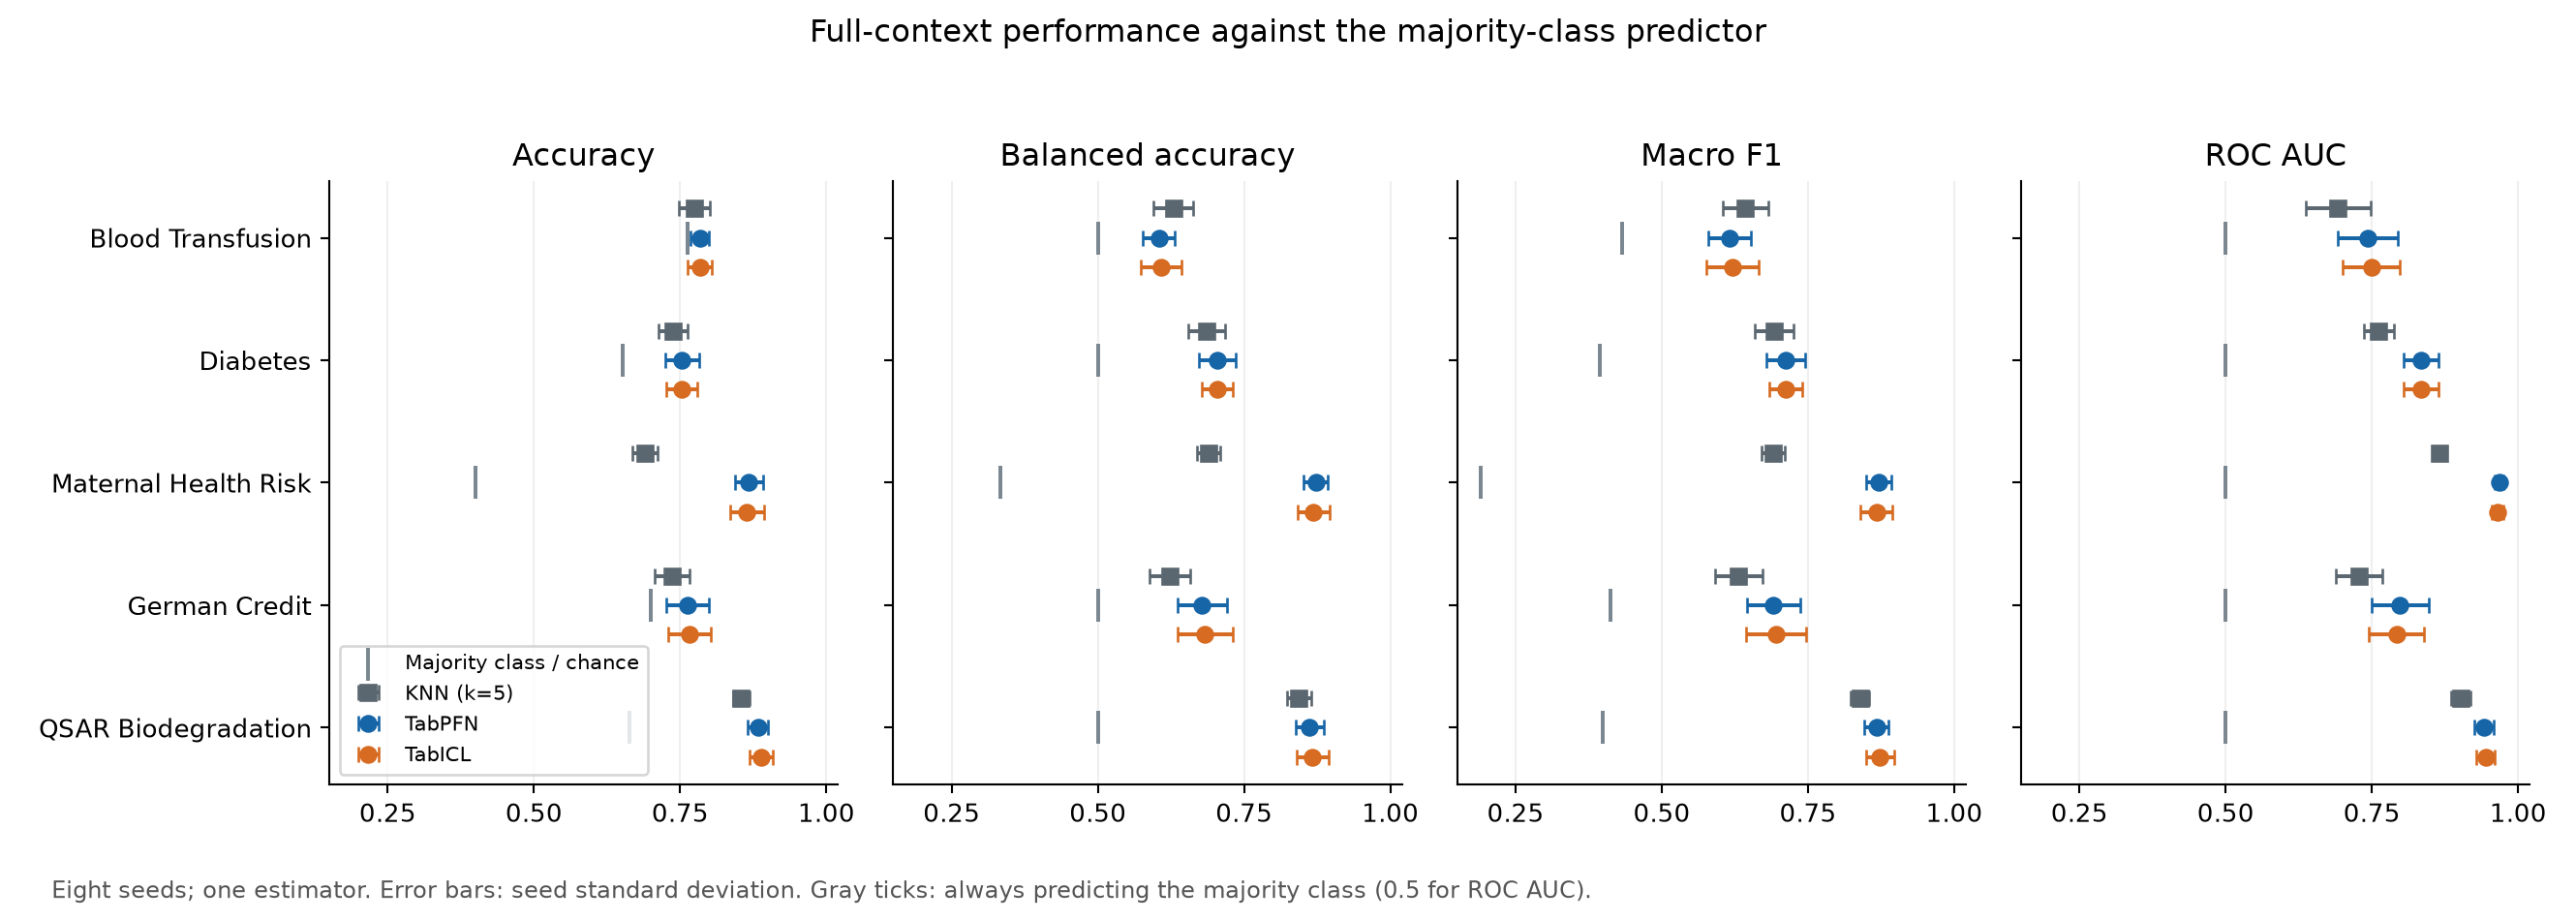

In [10]:
# Accuracy next to metrics that do not reward predicting the majority class.
panels = [("accuracy", "Accuracy", "majority_share"), ("balanced_accuracy", "Balanced accuracy", "majority_balanced_accuracy"),
          ("f1_macro", "Macro F1", "majority_f1_macro"), ("roc_auc", "ROC AUC", None)]
model_colors = {"knn": "#5b6770", **COLORS}
model_names = {"knn": "KNN (k=5)", **NAMES}
fig, axes = plt.subplots(1, 4, figsize=(14, 5), sharey=True)
for ax, (column, title, reference) in zip(axes, panels):
    for j, dataset in enumerate(DATASET_ORDER):
        ax.scatter(balance.loc[dataset, reference] if reference else 0.5, j, marker="|", s=160, color="#7b8790", zorder=4,
                   label="Majority class / chance" if j == 0 else None)
        for i, name in enumerate(["knn", *MODELS]):
            values = baseline[(baseline.dataset == dataset) & (baseline.model == name)][column]
            ax.errorbar(values.mean(), j + (i - 1) * 0.24, xerr=values.std(), fmt="s" if name == "knn" else "o",
                        color=model_colors[name], capsize=3, label=model_names[name] if j == 0 else None)
    ax.set(title=title, xlim=(0.15, 1.02))
    ax.set_xticks([0.25, 0.5, 0.75, 1])
    ax.grid(axis="x", alpha=0.2)
axes[0].set_yticks(range(5), [DATASET_NAMES[d] for d in DATASET_ORDER])
axes[0].invert_yaxis()
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Full-context performance against the majority-class predictor")
footer(fig, "Eight seeds; one estimator. Error bars: seed standard deviation. Gray ticks: always predicting the majority class (0.5 for ROC AUC).")
fig.tight_layout(rect=(0, 0.07, 1, 0.94))
save(fig, "12_imbalance_metrics", pdf)
display_png(OUTPUT / "12_imbalance_metrics.png")


Accuracy hides the class imbalance. On Blood Transfusion, 76% of rows are in one class,
and both foundation models score only about two points above always predicting it.
There, KNN has higher balanced accuracy, macro F1 and minority F1 than either foundation model,
although the foundation models have the higher ROC AUC. They rank cases better, but their predicted labels favor the majority class.
On the other four datasets the foundation models lead on every metric.


## Locality and attention mass


Created 01_locality_overview


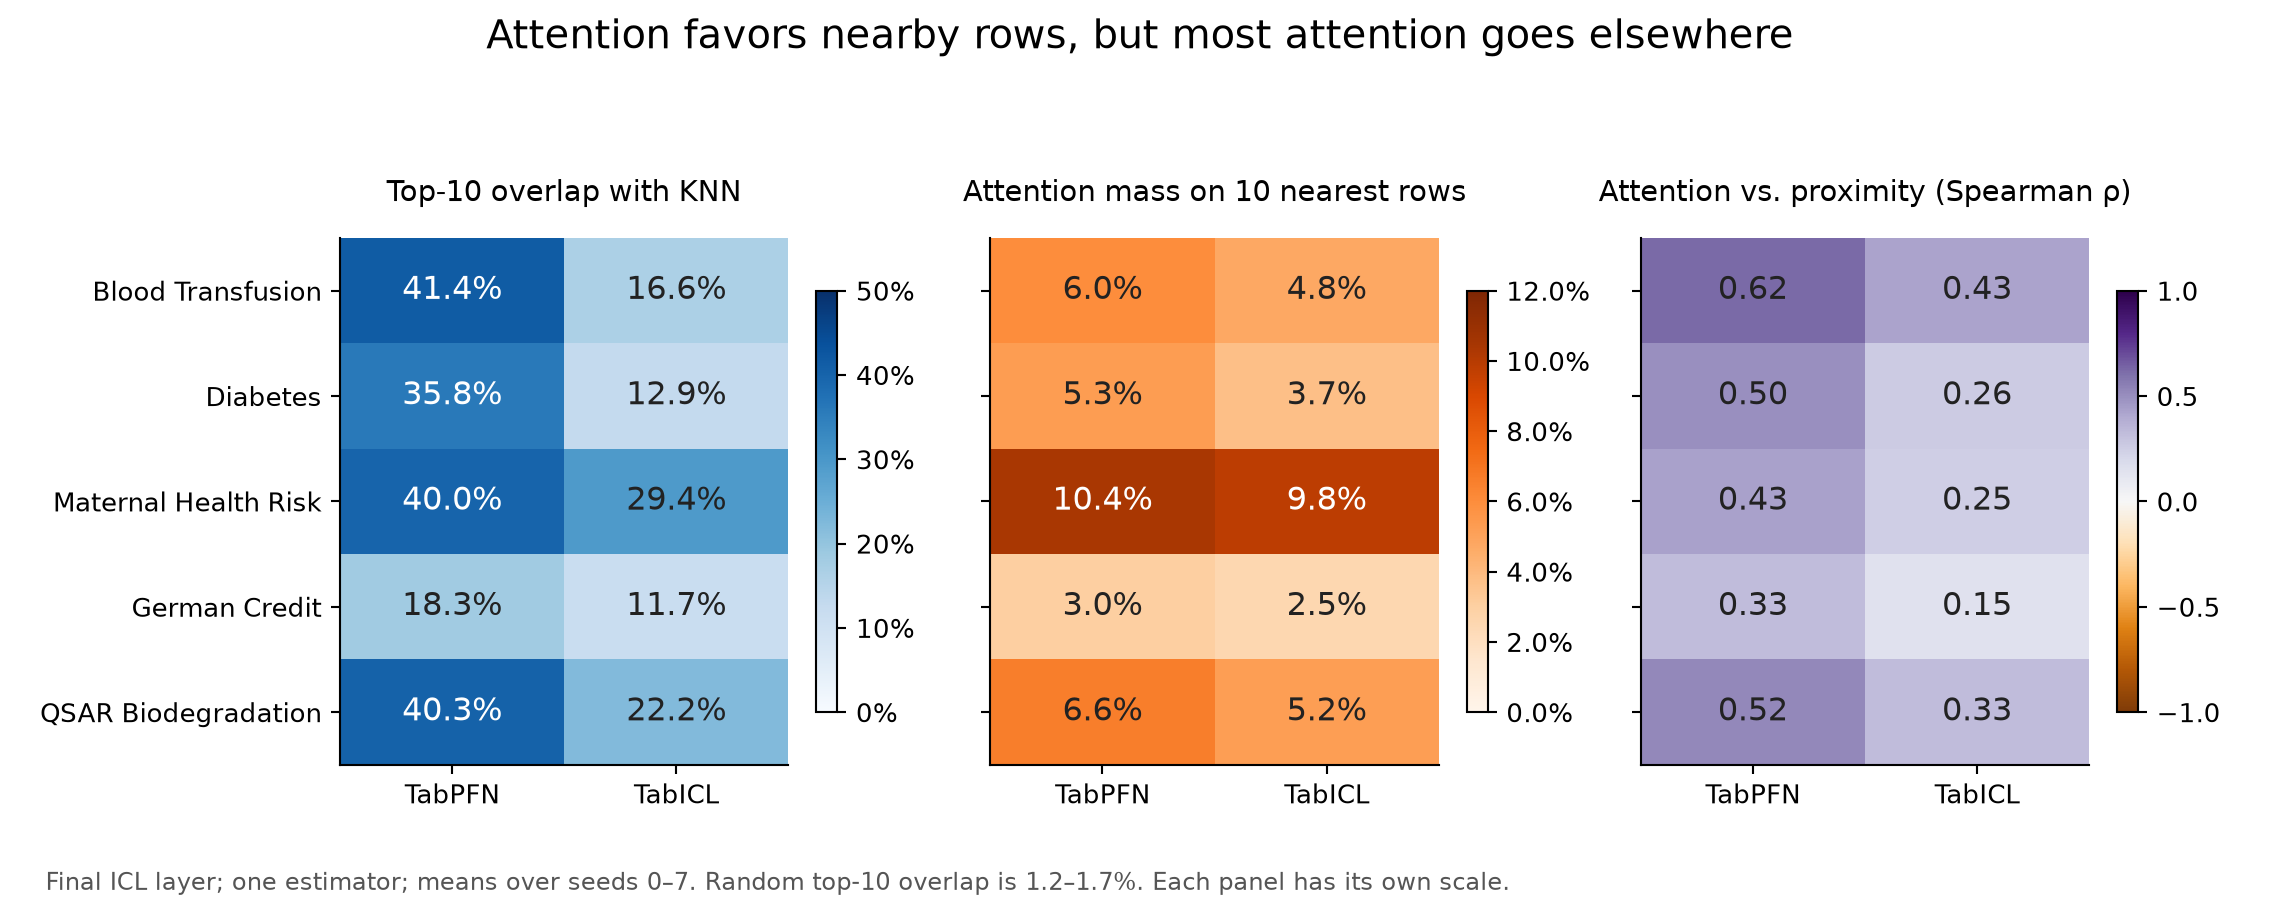

In [11]:
overview(last, pdf)
display_png(OUTPUT / "01_locality_overview.png")


TabPFN has more final-layer top-10 overlap than TabICL on every dataset.
Both exceed random overlap. The nearest ten rows receive only a small part of total attention.


## Where attention goes


Created 02_attention_concentration


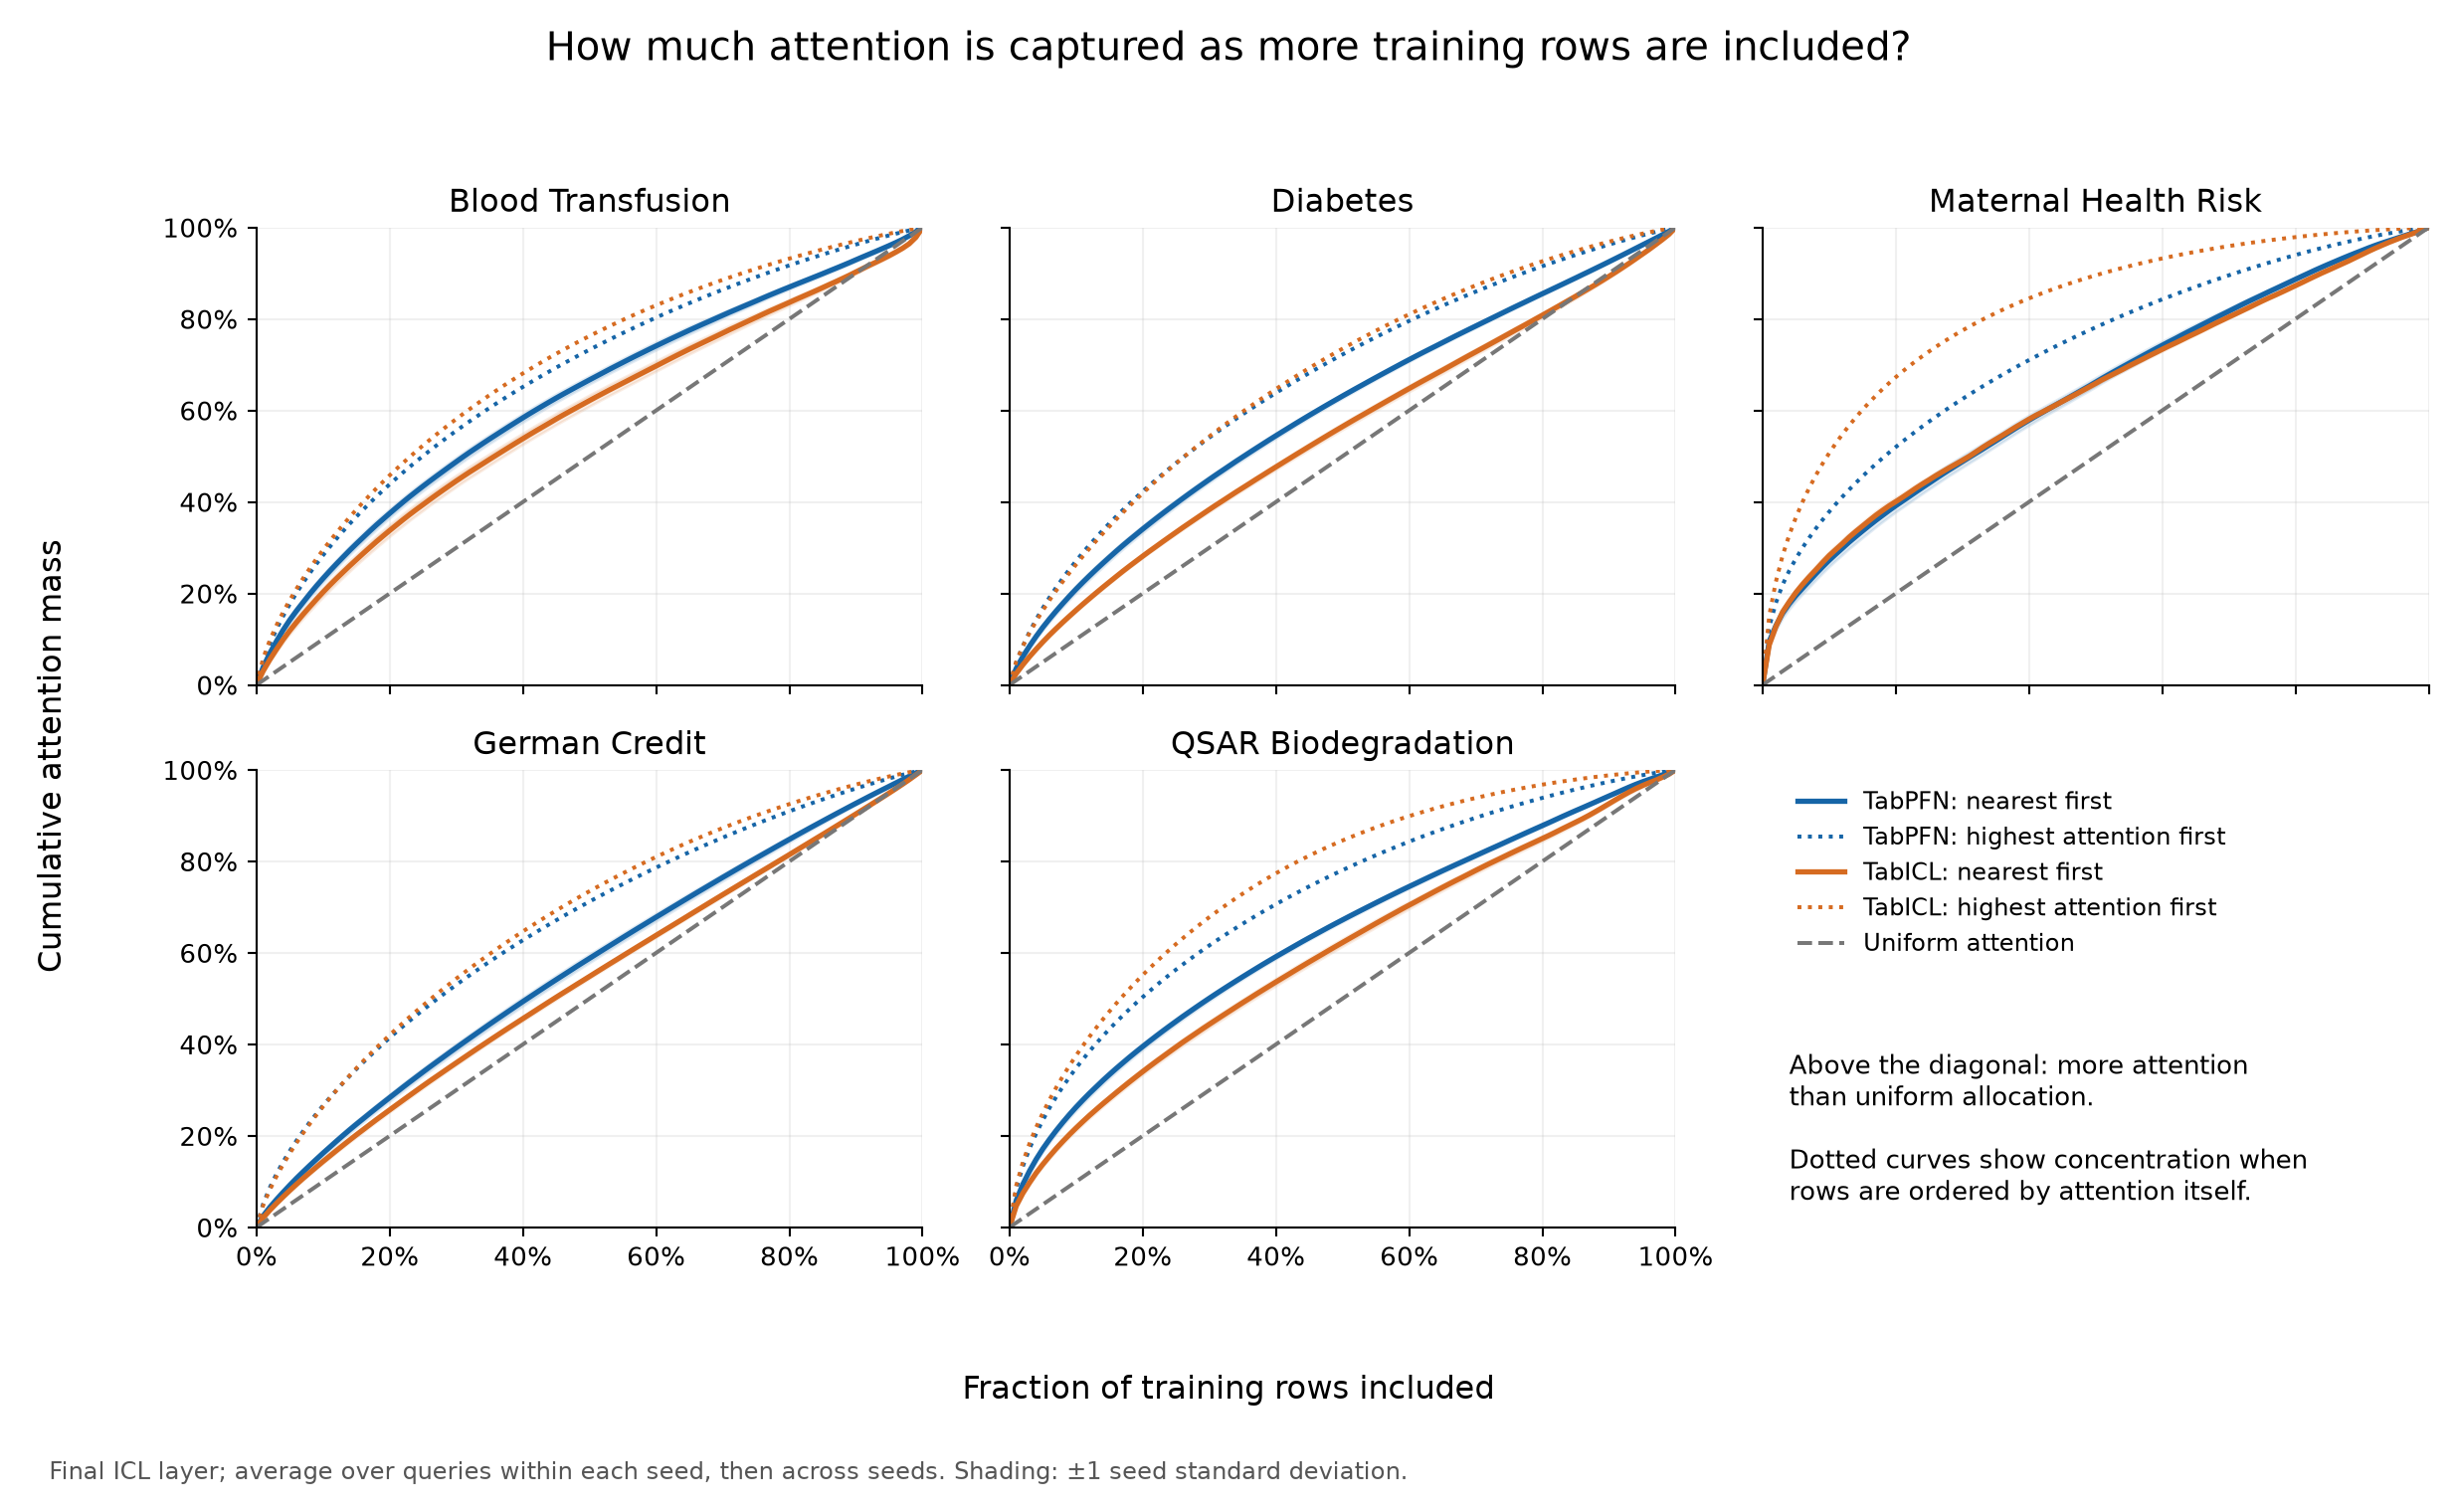

In [12]:
concentration(pdf)
display_png(OUTPUT / "02_attention_concentration.png")


Nearby rows receive more weight than uniform attention would give them.
The curves rise gradually, so attention also reaches distant rows. The dotted curves show that some highly weighted rows are not the nearest ones.


## Layers


Created 03_layer_heatmaps


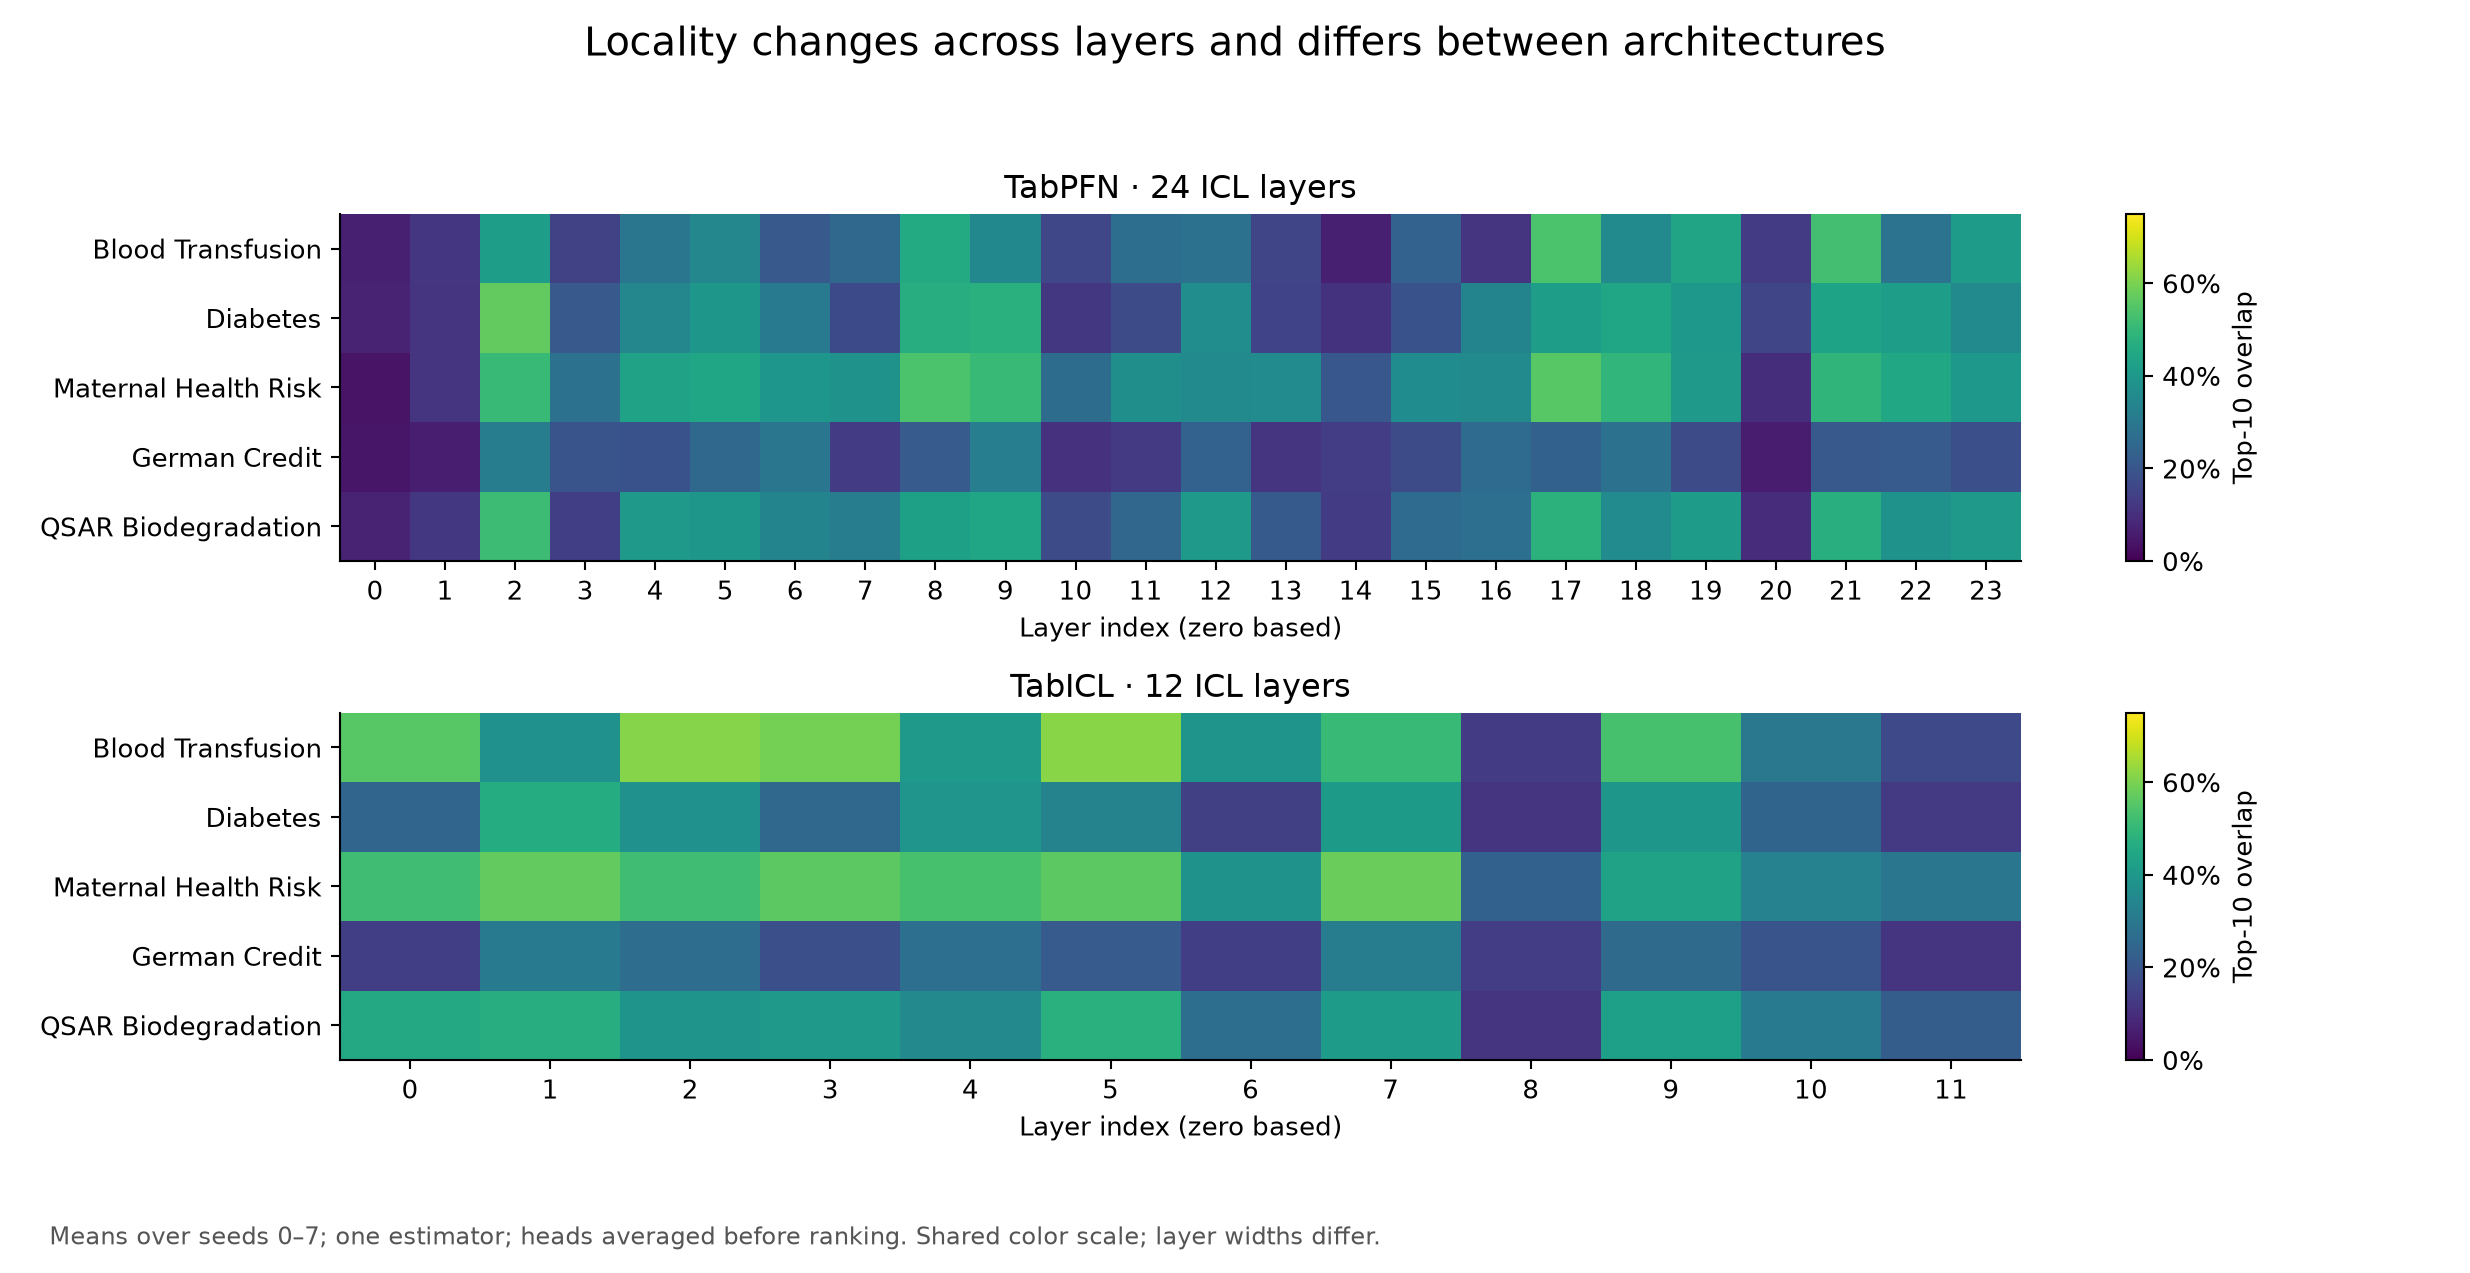

In [13]:
layers(summary, pdf)
display_png(OUTPUT / "03_layer_heatmaps.png")


TabPFN starts with low overlap and changes sharply between layers.
TabICL starts with stronger overlap and ends lower. The pattern is not a steady rise or fall.


Created 08_notebook_layer_curves


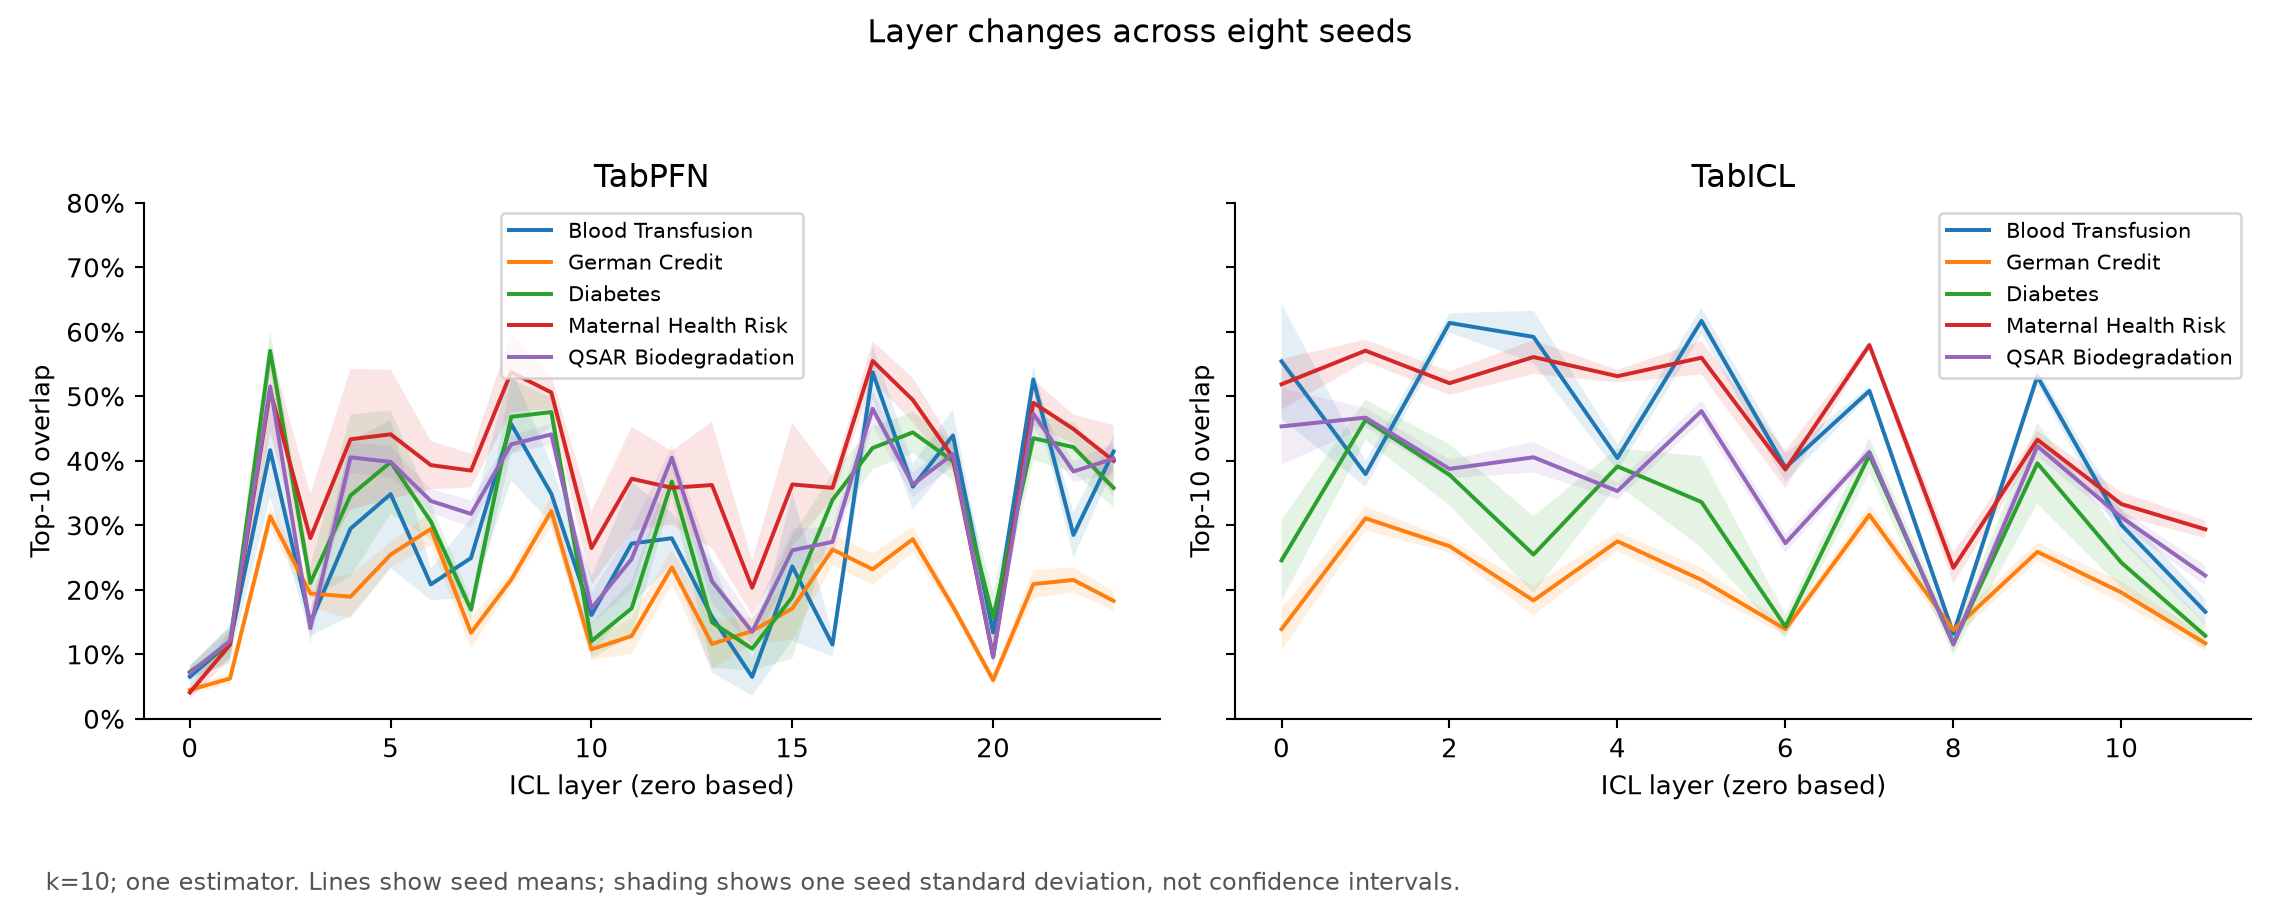

In [14]:
# Lines show the seed variation that the heatmap does not show.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, name in zip(axes, MODELS):
    part = summary[(summary.model == name) & (summary.k == 10)]
    for dataset, rows in part.groupby("dataset"):
        values = rows.groupby("layer").overlap.agg(["mean", "std"])
        mean, std = values["mean"], values["std"]
        ax.plot(values.index, mean, label=DATASET_NAMES[dataset])
        ax.fill_between(values.index, np.clip(mean-std, 0, 1), np.clip(mean+std, 0, 1), alpha=0.12)
    ax.set(title=NAMES[name], xlabel="ICL layer (zero based)", ylabel="Top-10 overlap", ylim=(0, 0.8))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
fig.suptitle("Layer changes across eight seeds")
footer(fig, "k=10; one estimator. Lines show seed means; shading shows one seed standard deviation, not confidence intervals.")
fig.tight_layout(rect=(0, 0.09, 1, 0.92))
save(fig, "08_notebook_layer_curves", pdf)
display_png(OUTPUT / "08_notebook_layer_curves.png")


## Differences between test points


Created 04_query_overlap_distributions


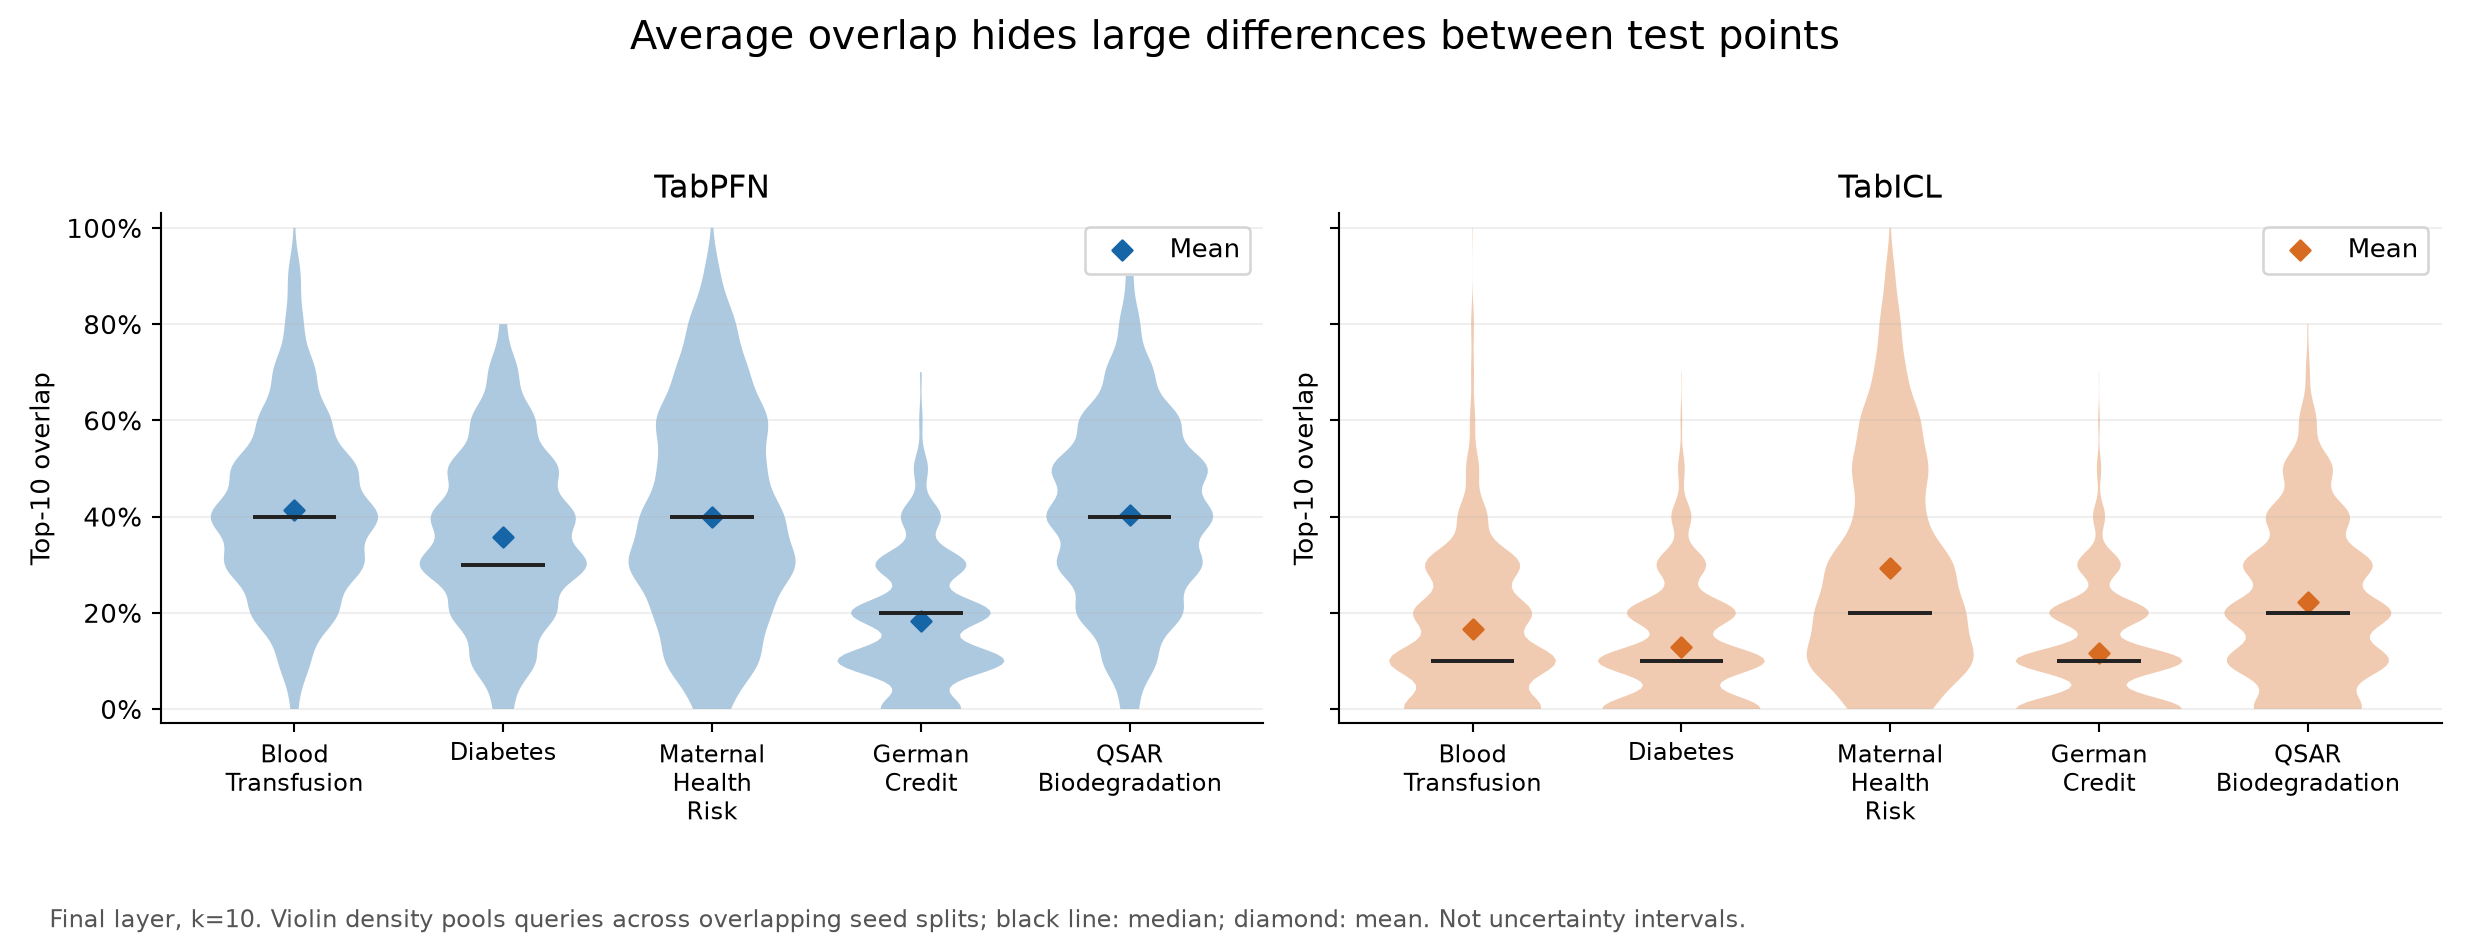

In [15]:
distributions(pdf)
display_png(OUTPUT / "04_query_overlap_distributions.png")


Overlap varies a lot between test points. Some have no shared neighbors.
A single mean hides this spread, especially for Maternal Health Risk.


## Prediction differences


Created 05_prediction_disagreements


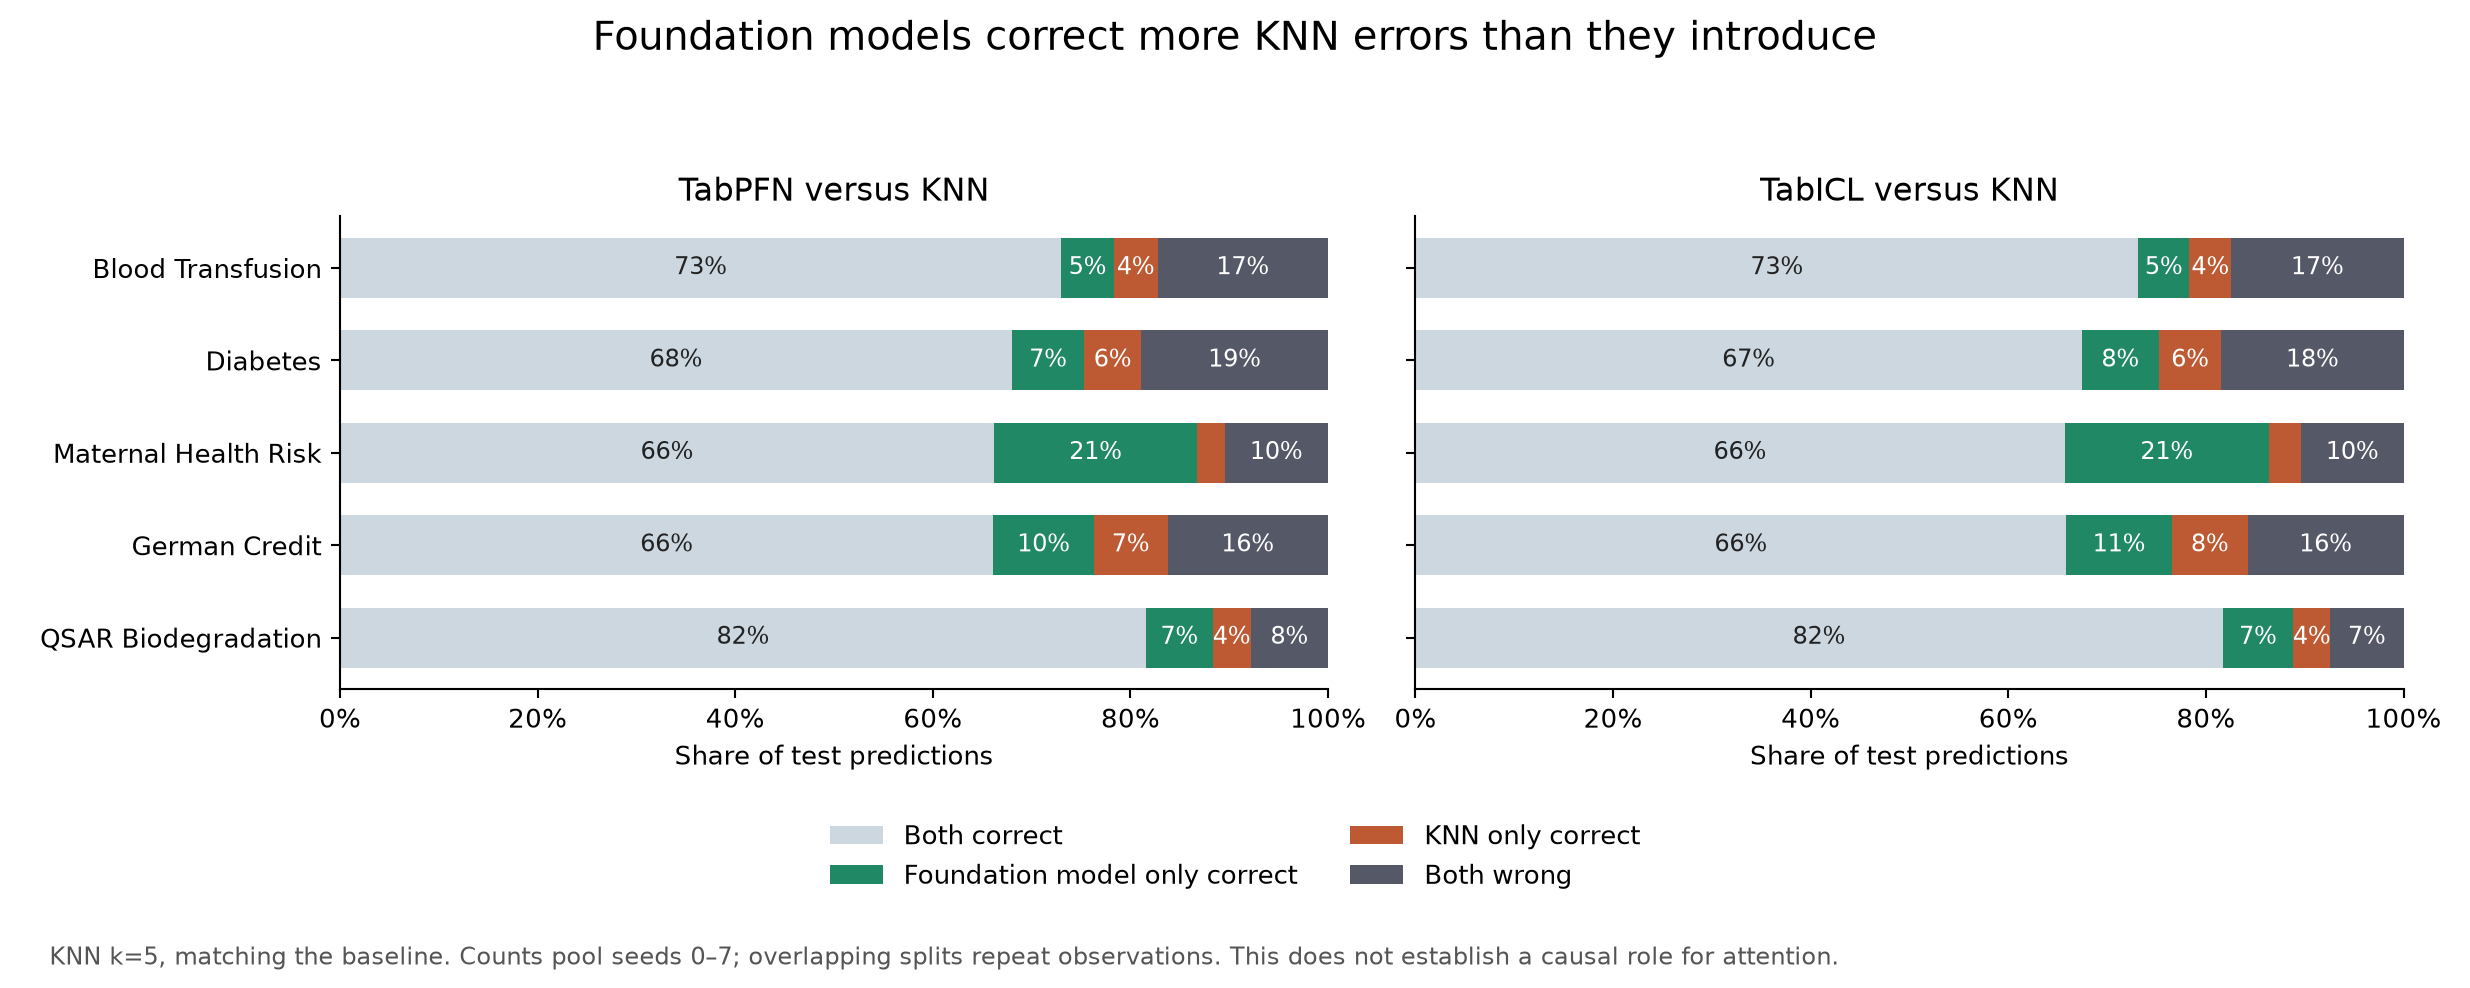

In [16]:
disagreements(pdf)
display_png(OUTPUT / "05_prediction_disagreements.png")


Both foundation models correct more KNN errors than they add.
This describes predictions. It does not show that attention causes the accuracy gain.


## Duplicates and ties


Created 06_duplicates_and_ties


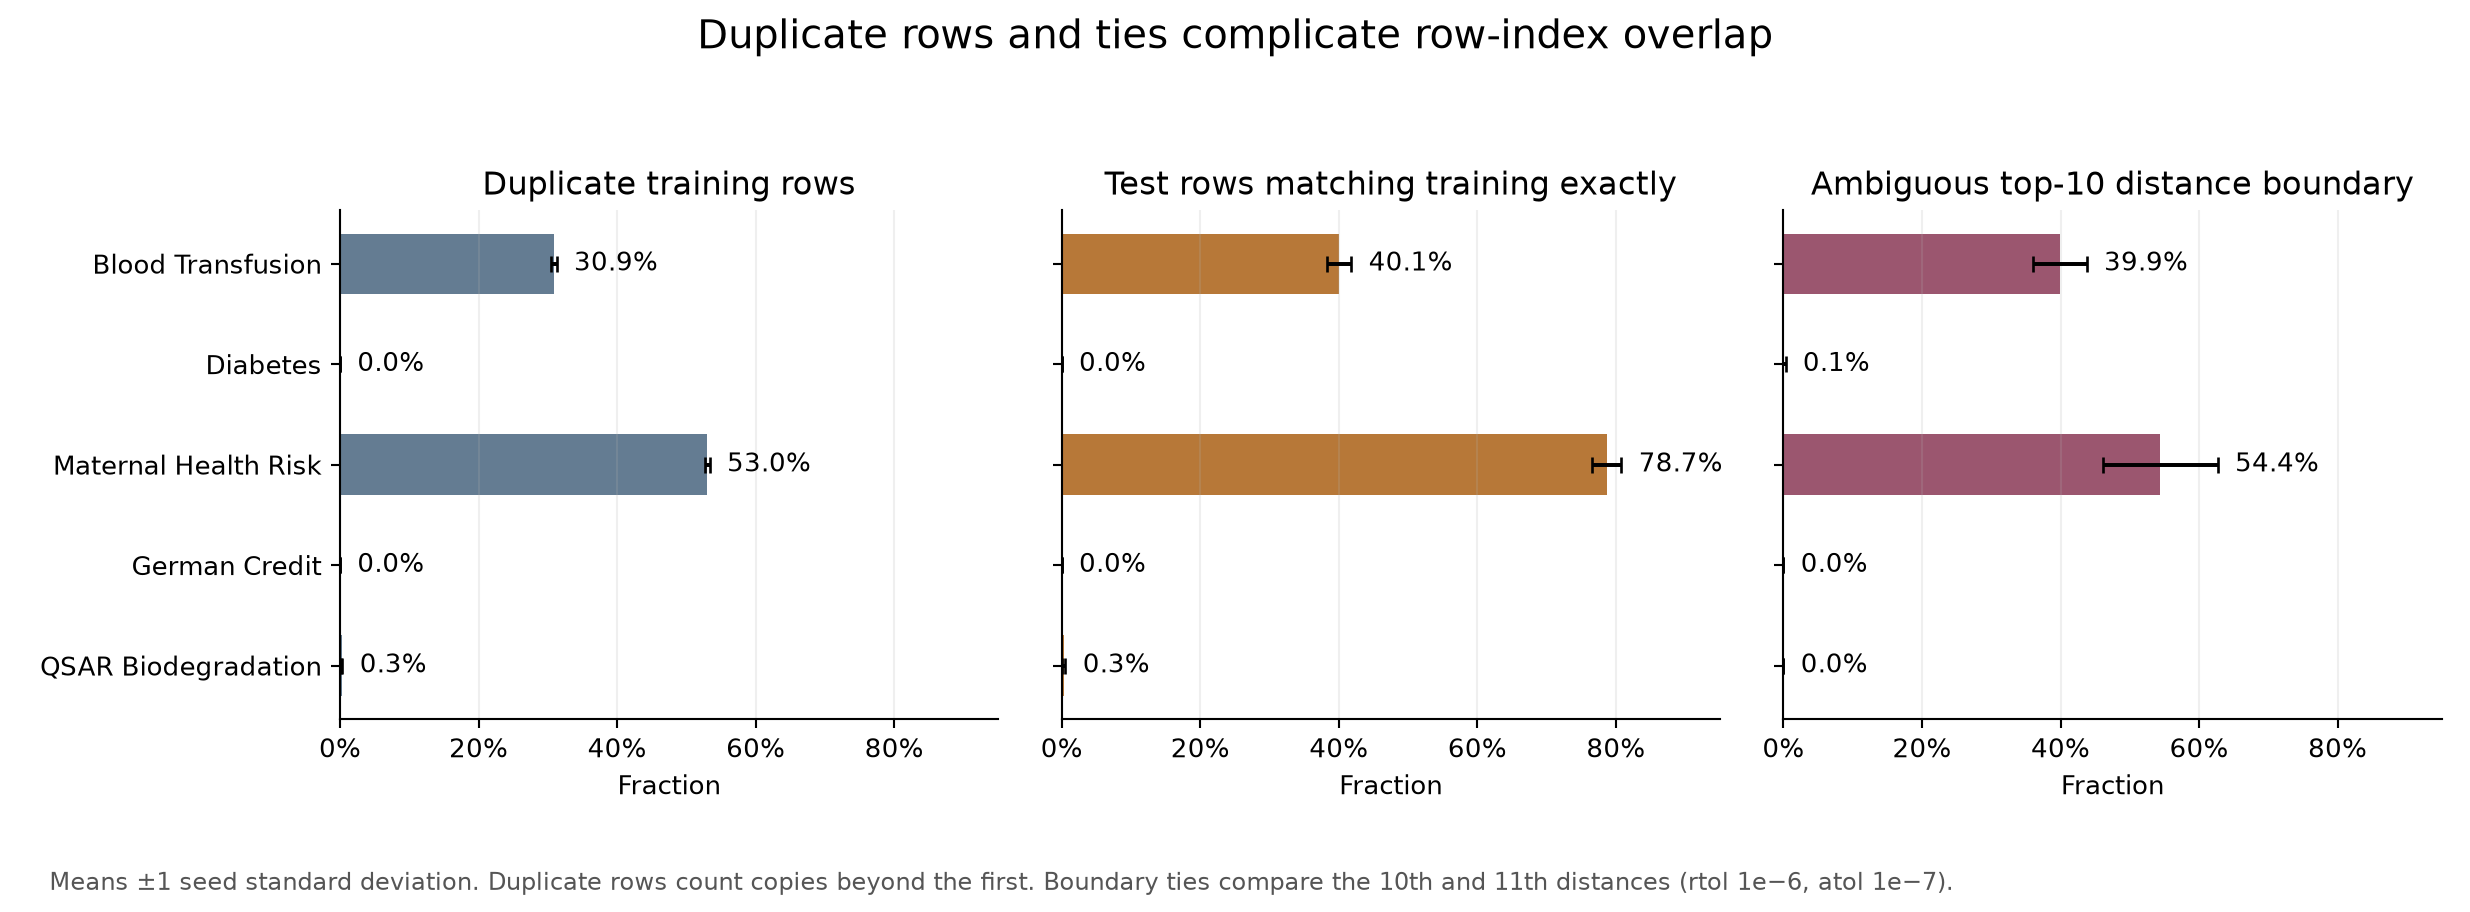

In [17]:
ties(pdf)
display_png(OUTPUT / "06_duplicates_and_ties.png")


Blood Transfusion and Maternal Health Risk have many repeated rows and distance ties.
Many Maternal Health Risk test rows exactly match a training row. Treat its accuracy and index overlap with care.


## Choice of k

Larger k gives larger sets. Random overlap also rises, so compare against the dashed line.
Bars show variation across seeds, not confidence intervals.


Created 07_notebook_overlap_by_k


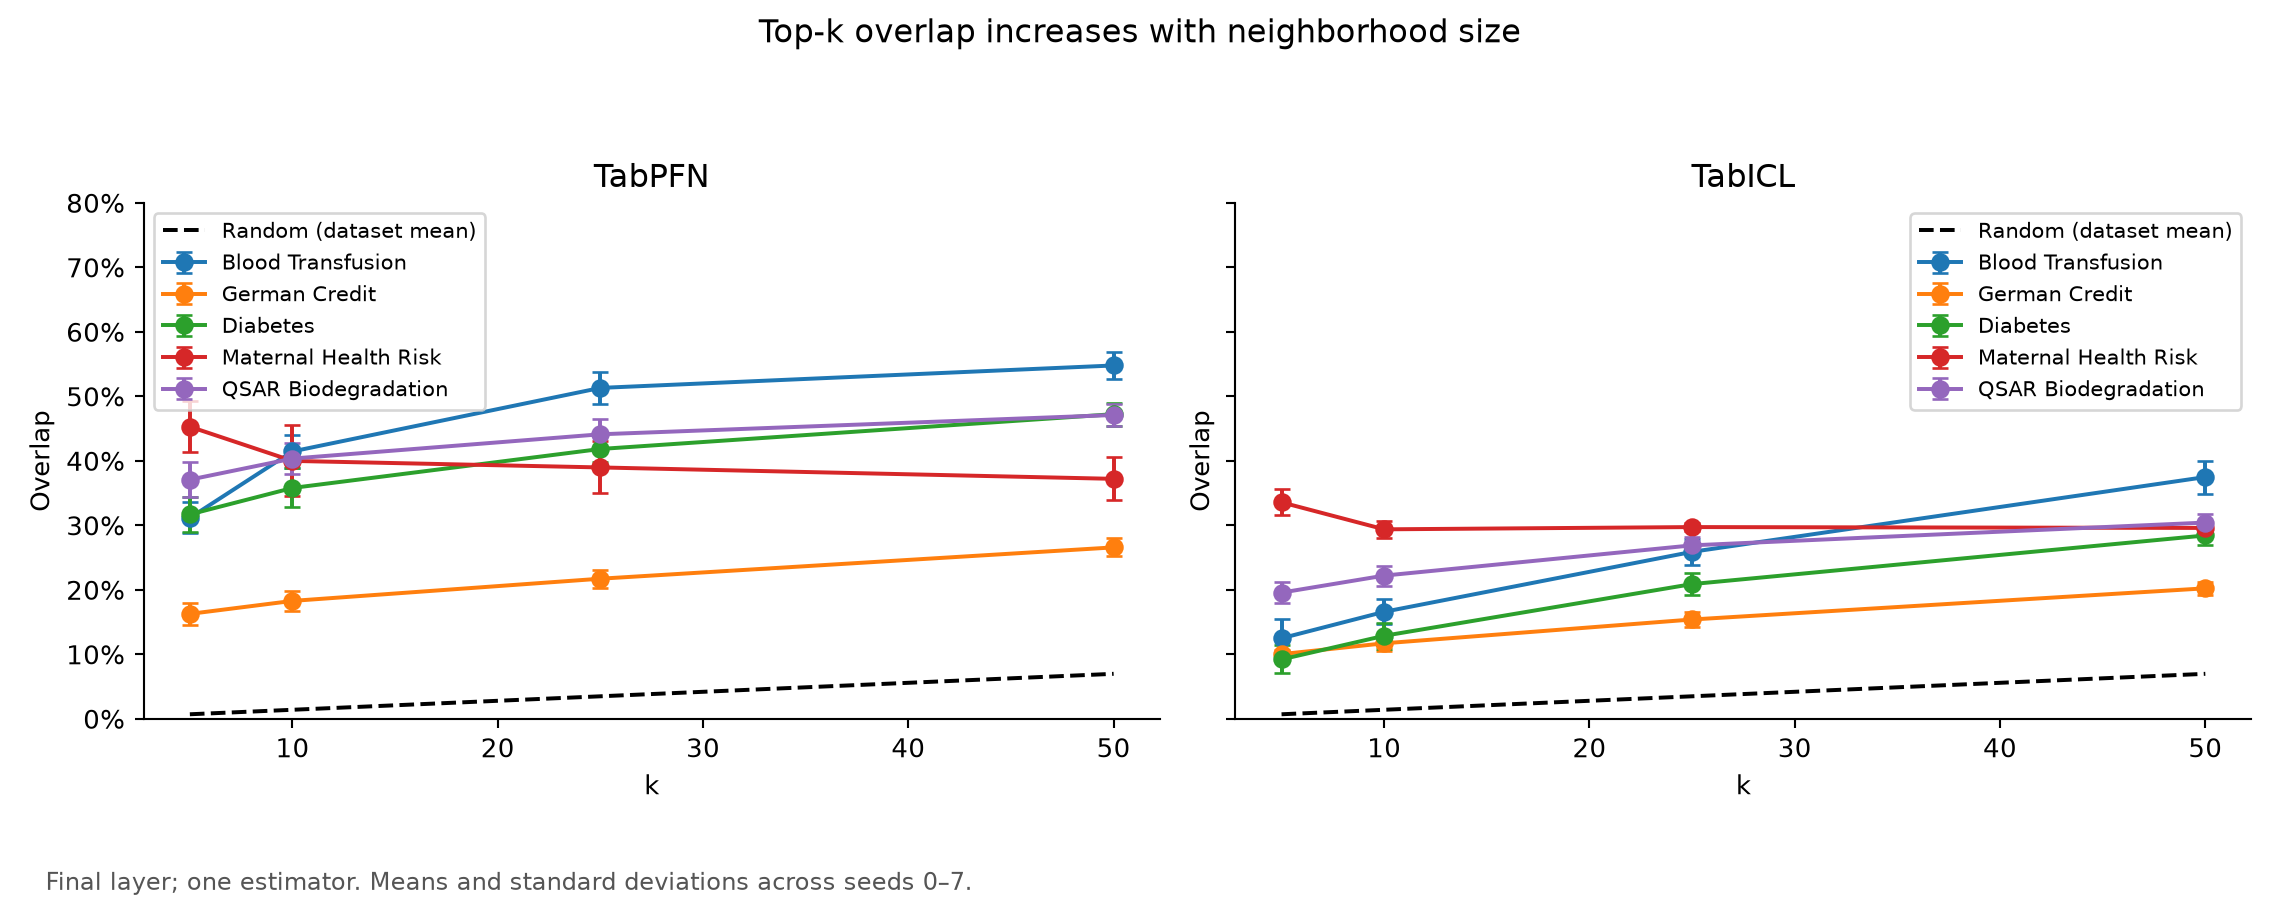

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, name in zip(axes, MODELS):
    part = last[last.model == name]
    for dataset, rows in part.groupby("dataset"):
        values = rows.groupby("k").overlap.agg(["mean", "std"])
        ax.errorbar(values.index, values["mean"], yerr=values["std"], marker="o", capsize=3,
                    label=DATASET_NAMES[dataset])
    random = part.groupby("k").random_overlap.mean()
    ax.plot(random.index, random, "k--", label="Random (dataset mean)")
    ax.set(title=NAMES[name], xlabel="k", ylabel="Overlap", ylim=(0, 0.8))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
fig.suptitle("Top-k overlap increases with neighborhood size")
footer(fig, "Final layer; one estimator. Means and standard deviations across seeds 0–7.")
fig.tight_layout(rect=(0, 0.09, 1, 0.92))
save(fig, "07_notebook_overlap_by_k", pdf)
display_png(OUTPUT / "07_notebook_overlap_by_k.png")


## Restricted context

Each test row gets only its nearest k training rows. Preprocessing is fitted again on that context.
Shared scaling and neighbor search still use the full training set. Only the model context is restricted.
Single-class contexts predict their class directly. Constant-feature contexts use a majority vote.
The fallback rates are reported, so these results are not pure model predictions for every row.


In [19]:
def restricted_context_accuracy(model_name, X_train, X_test, y_train, y_test, k, seed=0,
                                n_estimators=1, checkpoint_path=None, progress=None) -> dict:
    """For each test point, give the model only its k nearest training points.

    The model is skipped, and the neighbors' majority label predicted, when
    - all k neighbors share one label (most models refuse a single class), or
    - all k neighbors have identical features (TabPFN refuses constant features).
    The returned dict counts how often each shortcut was taken.
    """
    neighbors = knn_indices(X_train, X_test, k)
    preds = np.zeros(len(X_test), dtype=y_train.dtype)
    one_class = np.zeros(len(X_test), dtype=bool)
    constant = np.zeros(len(X_test), dtype=bool)
    start = 0
    signature = np.array([len(X_train), len(X_test), k, seed, n_estimators])
    checkpoint_path = Path(checkpoint_path) if checkpoint_path else None
    if checkpoint_path and checkpoint_path.exists():
        with np.load(checkpoint_path) as saved:
            np.testing.assert_array_equal(saved["signature"], signature)
            preds[:] = saved["preds"]
            one_class[:] = saved["one_class"]
            constant[:] = saved["constant"]
            start = int(saved["completed"])

    def save(completed):
        if checkpoint_path:
            checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
            temporary = checkpoint_path.with_suffix(".tmp.npz")
            np.savez(temporary, preds=preds, one_class=one_class, constant=constant,
                     completed=completed, signature=signature)
            temporary.replace(checkpoint_path)
        if progress:
            progress(completed, len(X_test))

    for i in range(start, len(X_test)):
        idx = neighbors[i]
        labels = y_train[idx]
        if len(np.unique(labels)) == 1:
            preds[i] = labels[0]
            one_class[i] = True
        elif np.all(np.ptp(X_train[idx], axis=0) == 0):
            preds[i] = np.bincount(labels).argmax()
            constant[i] = True
        else:
            model = make_model(model_name, k=min(k, len(idx)), seed=seed, n_estimators=n_estimators)
            model.fit(X_train[idx], labels)
            preds[i] = model.predict(X_test[i : i + 1])[0]
        if (i + 1) % 20 == 0 or i + 1 == len(X_test):
            save(i + 1)
    n_one_class, n_constant = int(one_class.sum()), int(constant.sum())
    n = len(X_test)
    return dict(
        **classification_metrics(y_test, preds),
        frac_one_class=n_one_class / n,
        frac_constant_features=n_constant / n,
        frac_model_used=(n - n_one_class - n_constant) / n,
    )


In [20]:
restricted_path = FINAL_RESULTS / "restricted_context.csv"
restricted_rows = pd.read_csv(restricted_path).to_dict("records") if restricted_path.exists() else []
if RERUN_RESTRICTED:
    restricted_rows = []
known = {(r["dataset"], r["seed"], r["model"], r["k"]) for r in restricted_rows}
assert all(r["n_estimators"] == N_ESTIMATORS for r in restricted_rows)
with cached_model_weights():
    for dataset in DATASET_ORDER:
        for seed in SEEDS:
            missing = [(name,k) for name in MODELS for k in KS if (dataset,seed,name,k) not in known]
            if not missing:
                continue
            if not RUN_MISSING and not RERUN_RESTRICTED:
                raise RuntimeError("Missing restricted runs. Set RUN_MISSING=True.")
            X, T, y, truth = get_split(dataset, seed=seed)
            for name,k in missing:
                # Fixed weights are reused; data preprocessing is refitted for each context.
                result = restricted_context_accuracy(name,X,T,y,truth,k,seed=seed,n_estimators=N_ESTIMATORS)
                restricted_rows.append(dict(dataset=dataset,seed=seed,model=name,k=k,n_estimators=N_ESTIMATORS,**result))
                pd.DataFrame(restricted_rows).to_csv(restricted_path,index=False)
restricted = pd.DataFrame(restricted_rows)
assert len(restricted) == 320
assert "f1_macro" in restricted, "Old restricted file without F1 columns. Run scripts/finalize_experiments.py."
local_full = restricted.merge(baseline[baseline.model != "knn"][["dataset","seed","model","accuracy","f1_macro"]].rename(
    columns={"accuracy":"full_accuracy","f1_macro":"full_f1_macro"}), on=["dataset","seed","model"], validate="many_to_one")
local_full["change_pp"] = 100 * (local_full.accuracy-local_full.full_accuracy)
local_full["f1_change"] = 100 * (local_full.f1_macro-local_full.full_f1_macro)
display(local_full.groupby(["dataset","model","k"])[["accuracy","change_pp","f1_macro","f1_change","frac_model_used"]].mean().round(3))


accuracy  change_pp  f1_macro  f1_change  \
dataset              model  k                                              
blood-transfusion    tabicl 5      0.698     -8.500     0.588     -3.222   
                            10     0.717     -6.667     0.602     -1.826   
                            25     0.743     -4.000     0.624      0.344   
                            50     0.757     -2.667     0.617     -0.314   
                     tabpfn 5      0.754     -2.917     0.623      0.705   
                            10     0.747     -3.667     0.616      0.049   
                            25     0.780     -0.333     0.644      2.815   
                            50     0.780     -0.333     0.635      1.913   
credit-g             tabicl 5      0.701     -6.500     0.624     -7.159   
                            10     0.709     -5.688     0.642     -5.352   
                            25     0.678     -8.813     0.619     -7.573   
                            50     0.711     -5.500     0.644     -5.144   
                     tabpfn 5      0.743     -2.000     0.650     -4.108   
                            10     0.754     -0.937     0.654     -3.691   
                            25     0.758     -0.500     0.639     -5.181   
                            50     0.757     -0.625     0.635     -5.590   
diabetes             tabicl 5      0.696     -5.682     0.668     -4.371   
                            10     0.663     -8.929     0.637     -7.486   
                            25     0.710     -4.221     0.677     -3.484   
                            50     0.741     -1.136     0.704     -0.804   
                     tabpfn 5      0.741     -1.218     0.697     -1.457   
                            10     0.730     -2.354     0.685     -2.639   
                            25     0.748     -0.487     0.700     -1.213   
                            50     0.752     -0.162     0.702     -0.954   
maternal-health-risk tabicl 5      0.823     -4.126     0.827     -3.999   
                            10     0.835     -2.894     0.839     -2.754   
                            25     0.842     -2.217     0.846     -2.143   
                            50     0.842     -2.155     0.846     -2.053   
                     tabpfn 5      0.813     -5.480     0.817     -5.326   
                            10     0.844     -2.340     0.848     -2.252   
                            25     0.836     -3.140     0.840     -3.041   
                            50     0.844     -2.340     0.848     -2.206   
qsar-biodeg          tabicl 5      0.816     -7.227     0.798     -7.503   
                            10     0.818     -7.109     0.800     -7.248   
                            25     0.838     -5.095     0.820     -5.299   
                            50     0.865     -2.370     0.846     -2.641   
                     tabpfn 5      0.858     -2.488     0.843     -2.394   
                            10     0.854     -2.903     0.838     -2.899   
                            25     0.877     -0.652     0.861     -0.577   
                            50     0.879     -0.415     0.863     -0.438   

                                frac_model_used  
dataset              model  k                    
blood-transfusion    tabicl 5             0.507  
                            10            0.692  
                            25            0.868  
                            50            1.000  
                     tabpfn 5             0.507  
                            10            0.692  
                            25            0.868  
                            50            1.000  
credit-g             tabicl 5             0.681  
                            10            0.870  
                            25            0.986  
                            50            0.999  
                     tabpfn 5             0.681  
                            10            0.870  
                            25         

Created 09_restricted_context


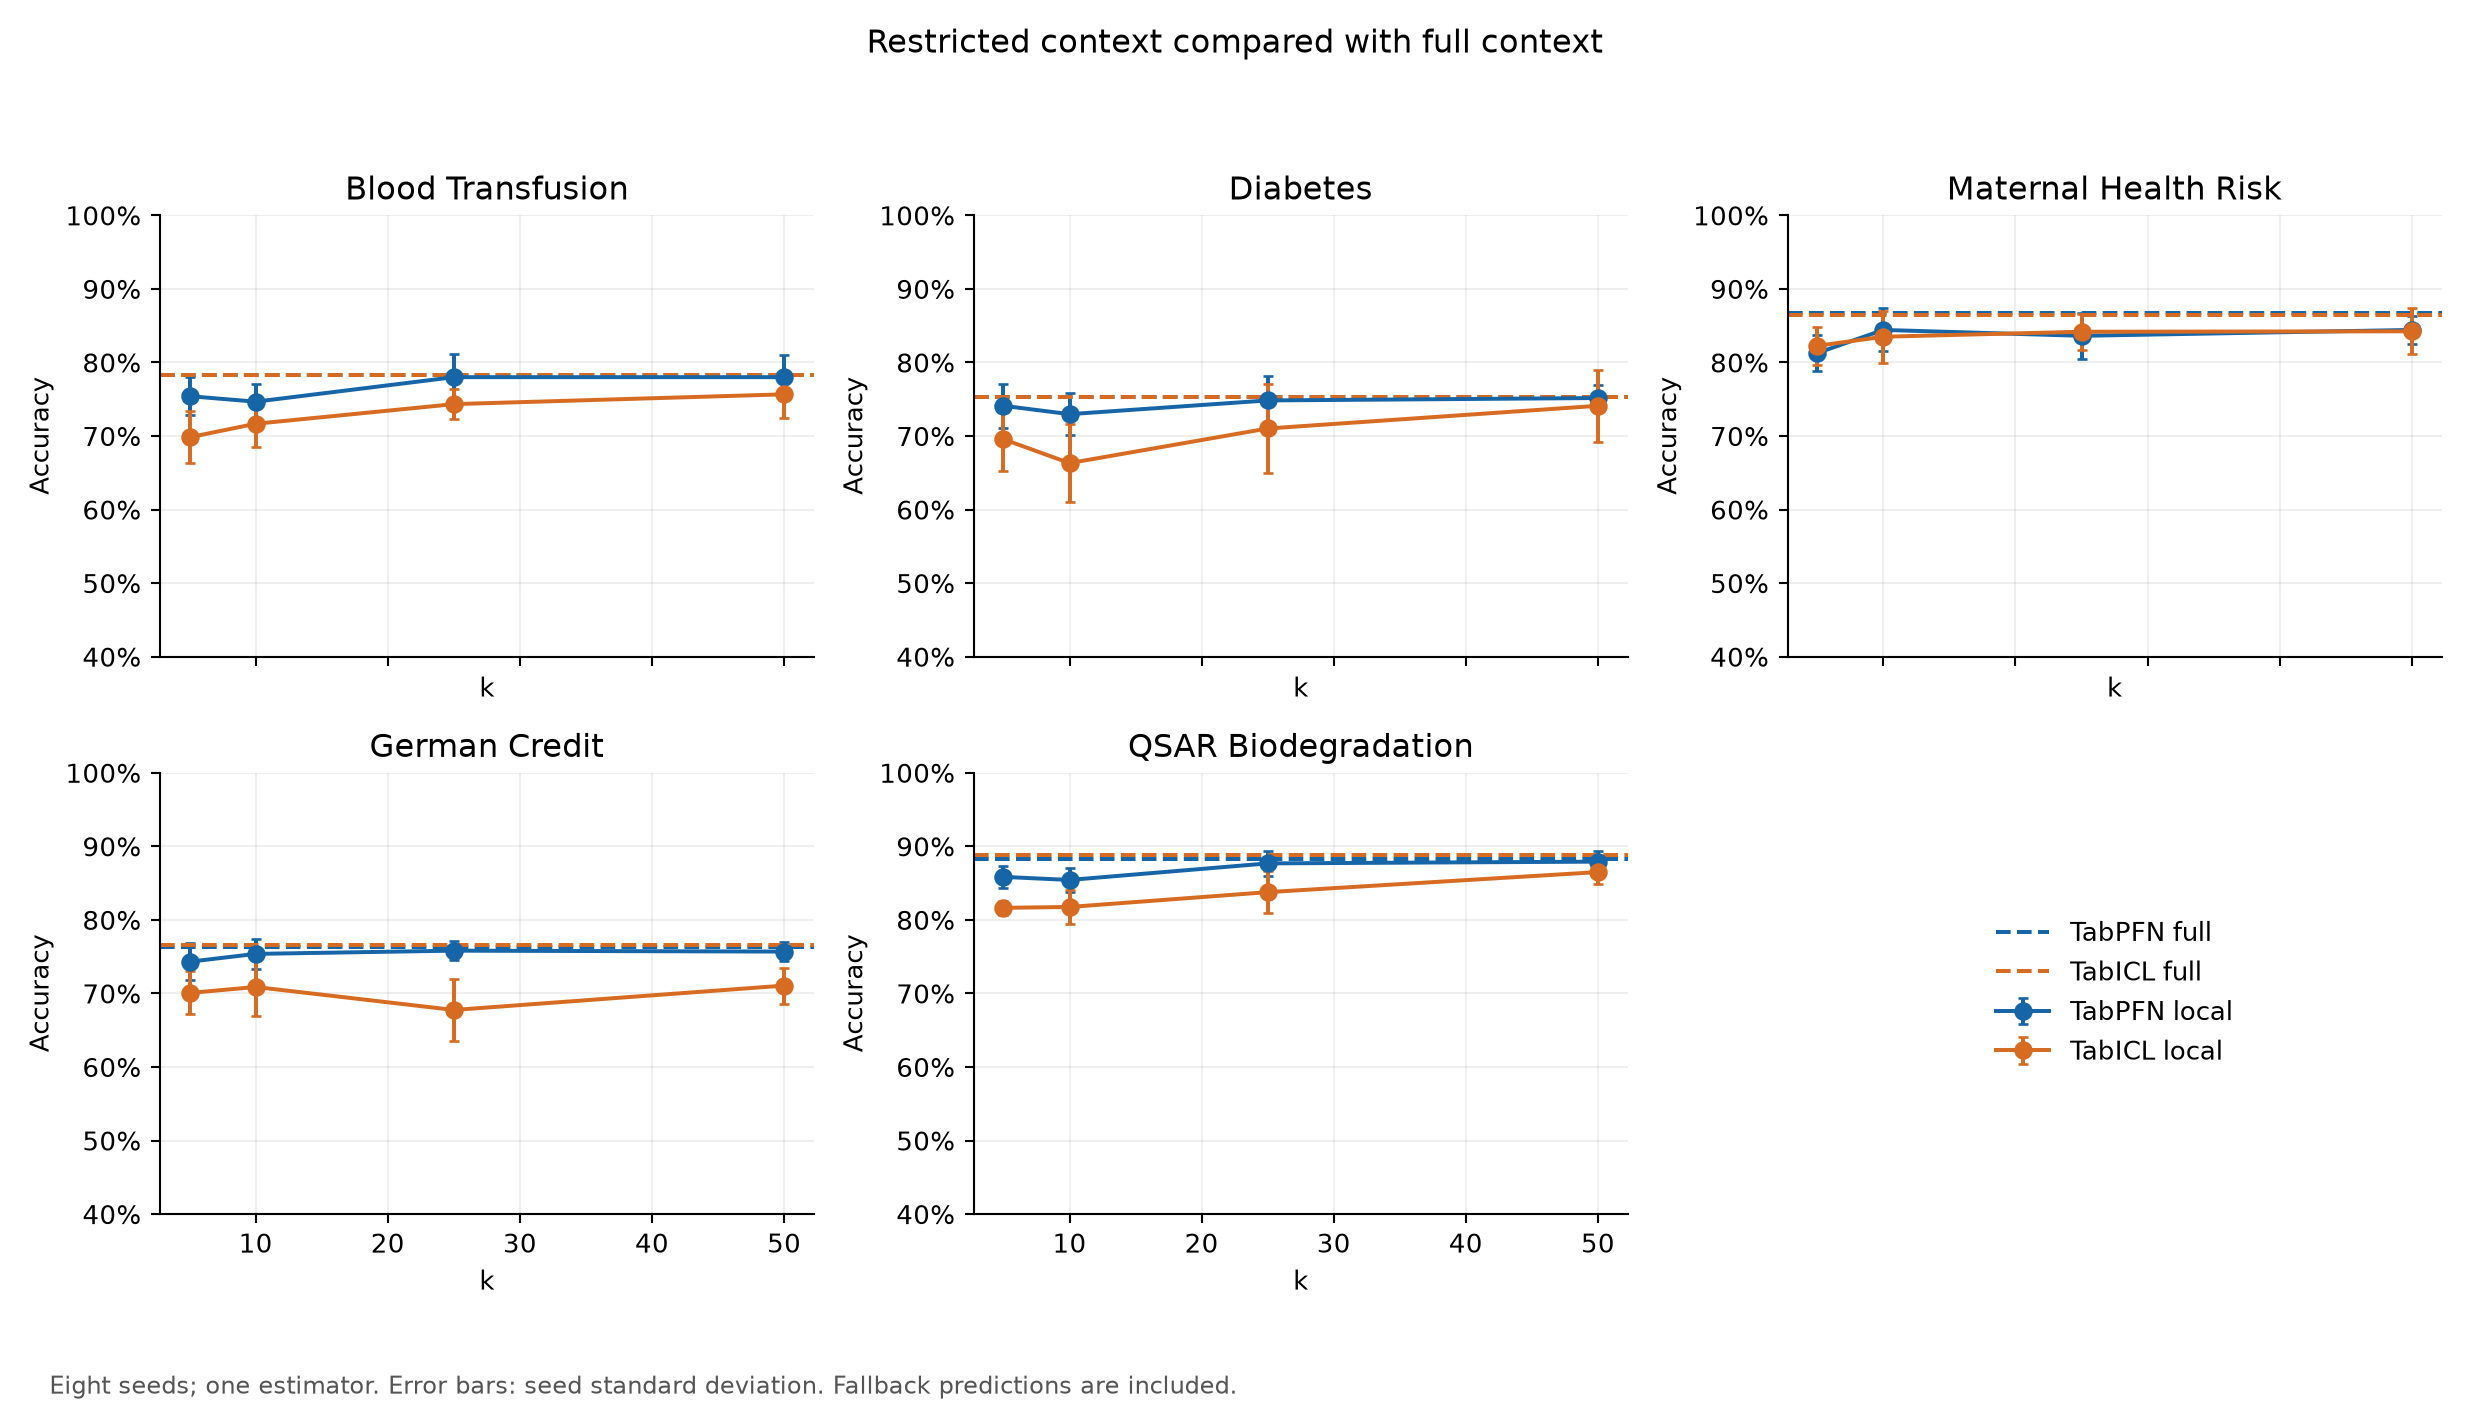

Created 11_restricted_accuracy_change


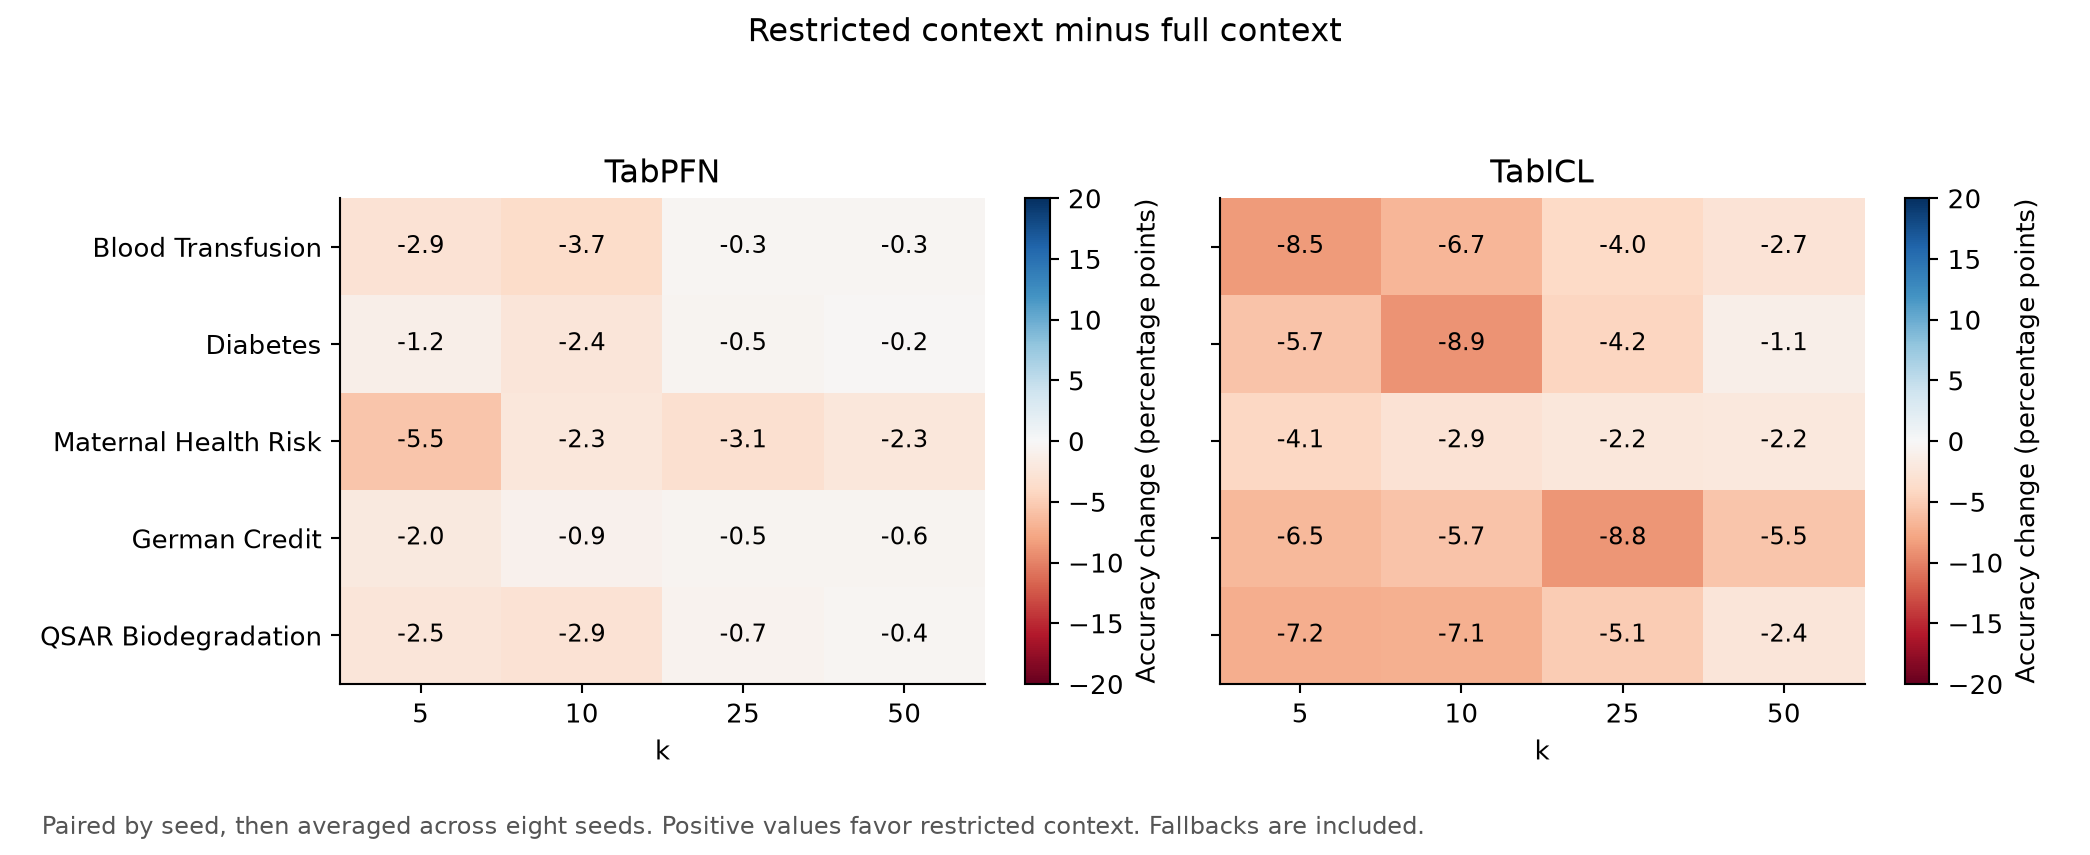

Created 13_restricted_f1_change


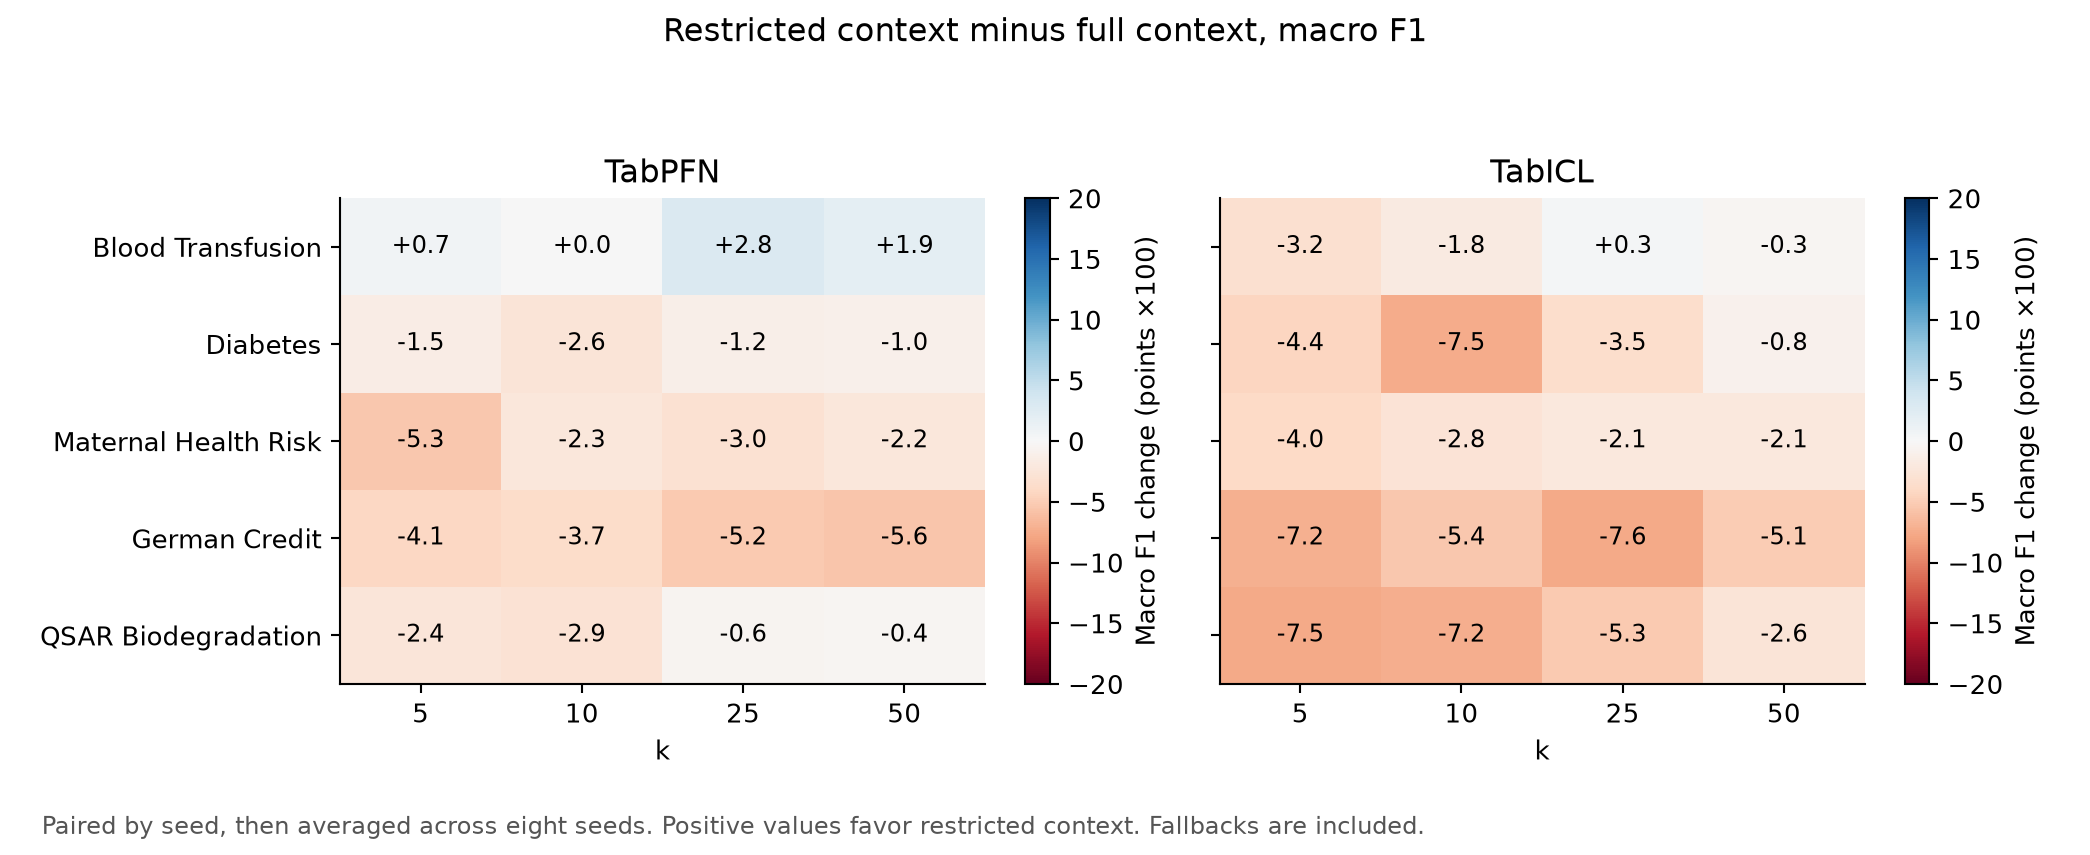

Created 10_knn_neighborhood_accuracy


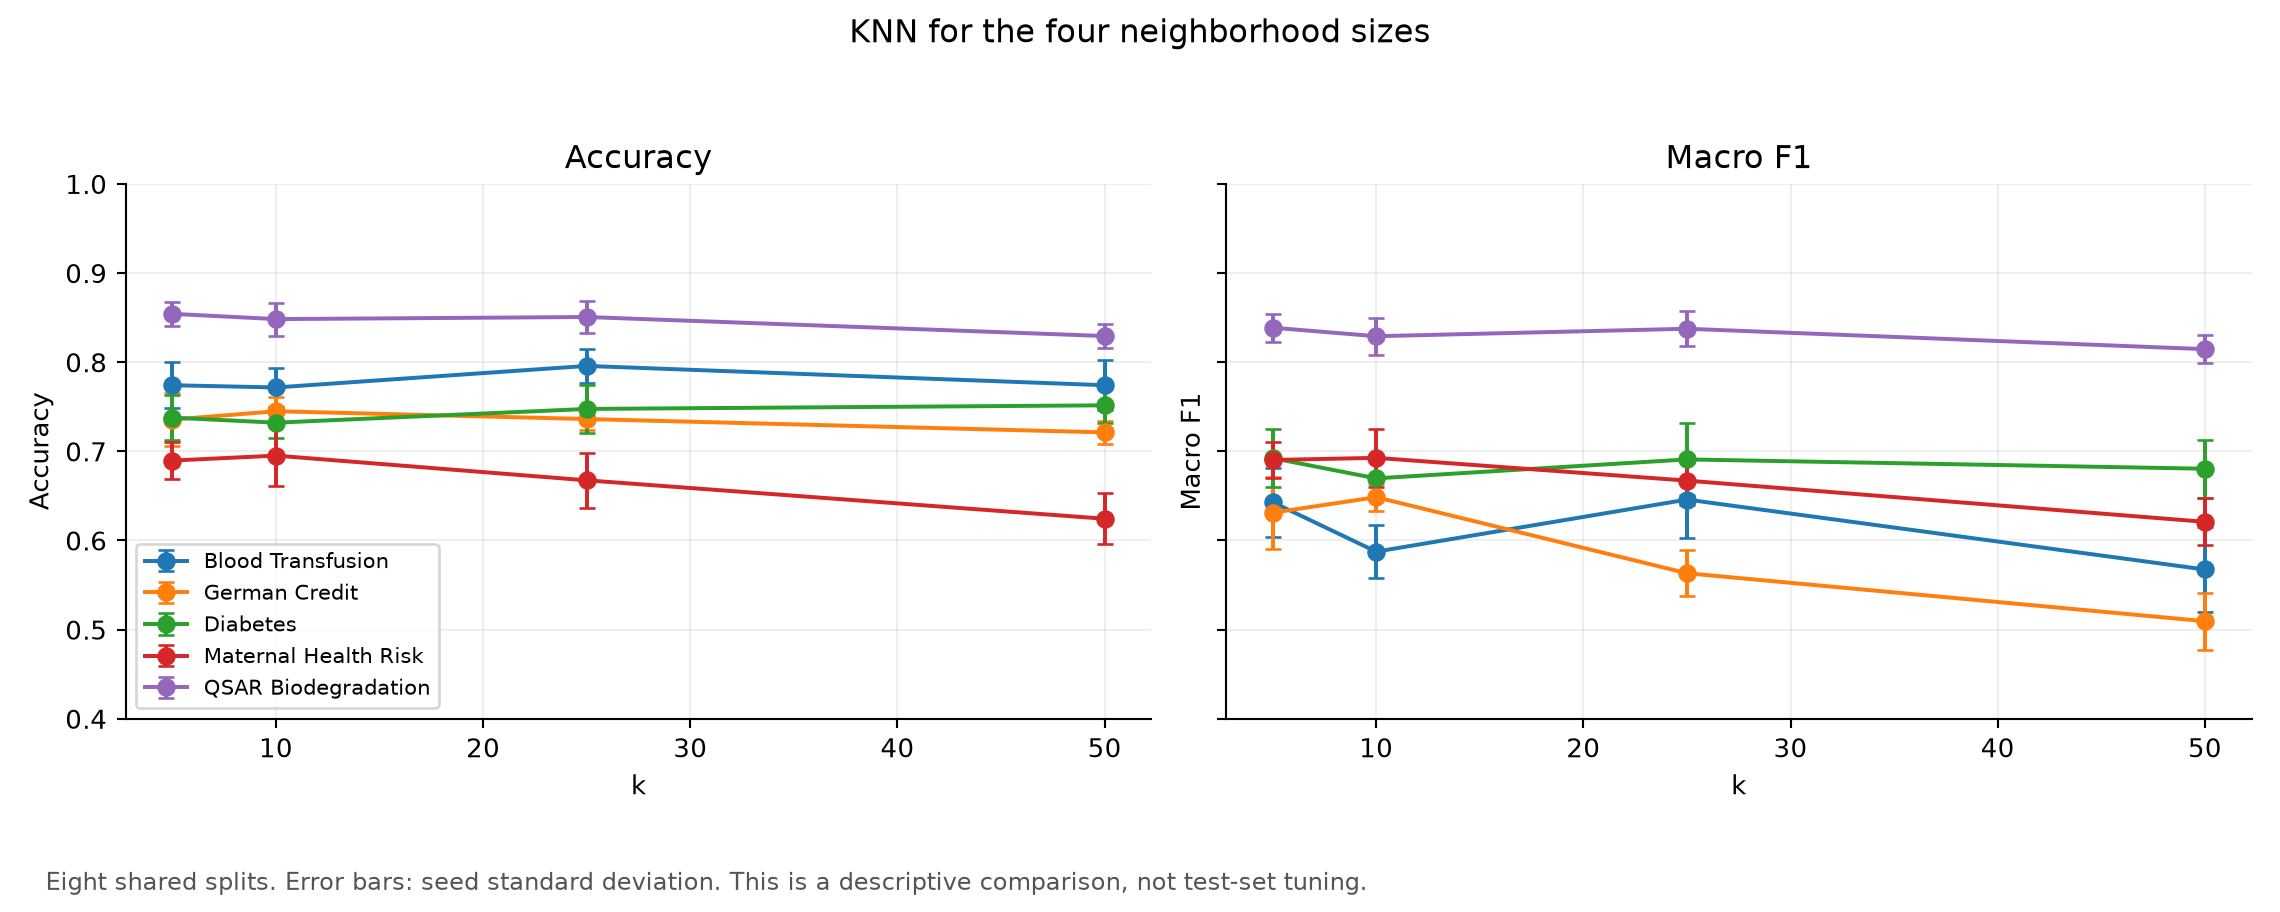

In [21]:
# Compare local accuracy with the matching full-context prediction.
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True)
for ax,dataset in zip(axes.flat,DATASET_ORDER):
    for name in MODELS:
        part=local_full[(local_full.dataset==dataset)&(local_full.model==name)]
        values=part.groupby("k").accuracy.agg(["mean","std"])
        ax.errorbar(values.index,values["mean"],yerr=values["std"],marker="o",capsize=2,color=COLORS[name],label=NAMES[name]+" local")
        ax.axhline(part.full_accuracy.mean(),color=COLORS[name],linestyle="--",label=NAMES[name]+" full")
    ax.set(title=DATASET_NAMES[dataset],xlabel="k",ylabel="Accuracy",ylim=(0.4,1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.2)
axes.flat[-1].axis("off")
handles,labels=axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles,labels,loc="center",frameon=False)
fig.suptitle("Restricted context compared with full context")
footer(fig,"Eight seeds; one estimator. Error bars: seed standard deviation. Fallback predictions are included.")
fig.tight_layout(rect=(0,0.07,1,0.94))
save(fig,"09_restricted_context",pdf)
display_png(OUTPUT/"09_restricted_context.png")

for column,stem,label,title in [("change_pp","11_restricted_accuracy_change","Accuracy change (percentage points)","Restricted context minus full context"),
                                ("f1_change","13_restricted_f1_change","Macro F1 change (points ×100)","Restricted context minus full context, macro F1")]:
    fig,axes=plt.subplots(1,2,figsize=(11,4.5),sharey=True)
    for ax,name in zip(axes,MODELS):
        changes=local_full[local_full.model==name].groupby(["dataset","k"])[column].mean().unstack().reindex(DATASET_ORDER)
        im=ax.imshow(changes,cmap="RdBu",vmin=-20,vmax=20,aspect="auto")
        ax.set_xticks(range(4),KS)
        ax.set_yticks(range(5),[DATASET_NAMES[d] for d in DATASET_ORDER])
        ax.set(title=NAMES[name],xlabel="k")
        for i in range(5):
            for j in range(4):
                ax.text(j,i,f"{changes.iloc[i,j]:+.1f}",ha="center",va="center",fontsize=9)
        fig.colorbar(im,ax=ax,label=label)
    fig.suptitle(title)
    footer(fig,"Paired by seed, then averaged across eight seeds. Positive values favor restricted context. Fallbacks are included.")
    fig.tight_layout(rect=(0,0.07,1,0.92))
    save(fig,stem,pdf)
    display_png(OUTPUT/f"{stem}.png")

fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,(column,label) in zip(axes,[("accuracy","Accuracy"),("f1_macro","Macro F1")]):
    for dataset,part in knn_grid.groupby("dataset"):
        values=part.groupby("k")[column].agg(["mean","std"])
        ax.errorbar(values.index,values["mean"],yerr=values["std"],marker="o",capsize=3,label=DATASET_NAMES[dataset])
    ax.set(xlabel="k",ylabel=label,title=label,ylim=(0.4,1))
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle("KNN for the four neighborhood sizes")
footer(fig,"Eight shared splits. Error bars: seed standard deviation. This is a descriptive comparison, not test-set tuning.")
fig.tight_layout(rect=(0,0.09,1,0.94))
save(fig,"10_knn_neighborhood_accuracy",pdf)
display_png(OUTPUT/"10_knn_neighborhood_accuracy.png")
pdf.close()


The dashed lines use the same full-context splits. A gap below a dashed line means local context lowers accuracy.
This tests the full context-selection pipeline, including its preprocessing and fallback rules.
Full context has higher mean accuracy in all tested dataset, model, and k combinations.
Larger contexts often reduce the gap, but the change is not always steady.

Macro F1 mostly tells the same story, with one exception. On Blood Transfusion, local context
lowers TabPFN's accuracy but slightly raises its mean macro F1, within one seed standard deviation.
On German Credit, TabPFN's macro F1 loss is larger than its accuracy loss.


## What we learned

Attention and Euclidean neighbors are related, but they do not select the same rows.
Most attention lies outside the nearest ten rows. The pattern depends on layer and dataset.
Attention alone cannot explain why a prediction is correct.

The seeds reuse some observations. Error bars are not evidence of statistical significance.
Duplicate rows and head averaging also limit the comparison.
Every dataset is imbalanced. Accuracy alone flatters the foundation models on Blood Transfusion.
All baseline, attention, and restricted-context cases use eight seeds and one estimator.
KNN is also compared at k=5, 10, 25, and 50. These values were not selected using test accuracy.

## Export

This notebook has saved tables and figures. Export it to HTML with Jupyter, or run:

    jupyter nbconvert --to html notebooks/attention_analysis.ipynb

For PDF, print the HTML to PDF in a browser. Hide code during HTML export with:

    jupyter nbconvert --to html --no-input notebooks/attention_analysis.ipynb
